---
title: "Análisis Exploratorio de Datos: Ruta Calle 72"
---

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from dotenv import load_dotenv
from IPython.display import display
import json
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, Polygon
from shapely.geometry import shape
import io
import base64
from IPython.display import HTML, display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
pd.set_option("display.max_columns", None)

load_dotenv() 

True

In [2]:
engine = create_engine(
    f"postgresql+psycopg://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}",
    connect_args={"options": "-c default_transaction_read_only=on"},  # solo lectura
)

In [3]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

SRC_PATH = PROJECT_ROOT / "src"
DATA_RAW = PROJECT_ROOT /"data"  /"raw"
DATA_PROCESSED = PROJECT_ROOT / "data" /"processed"

if str(SRC_PATH) not in sys.path:
    sys.path.append(str(SRC_PATH))

from utils import eda_toolkit as toolkit

In [ ]:
def _style_axes(ax, tick_size):
    _style_spines(ax)
    _style_ticks(ax, tick_size)


def _style_spines(ax, color="black", linewidth=0.8):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(color)
        spine.set_linewidth(linewidth)


def _style_ticks(ax, tick_size):
    ax.tick_params(axis="x", which="both", bottom=True, labelsize=tick_size,
                   direction="out", length=4, width=0.8, colors="black")
    ax.tick_params(axis="y", which="both", left=True, labelsize=tick_size,
                   direction="out", length=4, width=0.8, colors="black")


def render_figure(fig, fmt="svg", dpi=100):
    """Render a matplotlib figure inline as centered HTML."""
    if fmt not in ("svg", "png"):
        raise ValueError(f"'fmt' must be 'svg' or 'png', got '{fmt}'.")
    buf = io.BytesIO()
    if fmt == "svg":
        fig.savefig(buf, format="svg", bbox_inches="tight")
        plt.close(fig)
        display(HTML('<div style="display: flex; justify-content: center; width: 100%;">'
                     + buf.getvalue().decode("utf-8") + "</div>"))
    else:
        fig.savefig(buf, format="png", bbox_inches="tight", dpi=dpi)
        plt.close(fig)

        encoded = base64.b64encode(buf.getbuffer()).decode("ascii")
        display(HTML(f'<div style="text-align: center; width: 100%;">'
                     f'<img src="data:image/png;base64,{encoded}"></div>'))

def plot_acf_pacf(
    series,
    titulos=("Autocorrelación (ACF)", "Autocorrelación parcial (PACF)"),
    xlab="Rezago",
    ylab="Autocorrelación",
    lags=100,
    ylim=(-1.1, 1.1),
    figsize=(10, 4),
    label_size=11,
    title_size=12,
    tick_size=10,
    color="black",
    band_color="lightgray",
    band_alpha=0.3,
    render=True,
    fmt="svg",
    dpi=100,
):
    """Gráfico de ACF y PACF en paralelo.

    Dibuja la función de autocorrelación y la función de autocorrelación
    parcial de la serie recibida usando ``statsmodels``. Aplica el mismo
    estilo que el resto de los gráficos del proyecto: líneas negras,
    bandas de confianza en gris claro, y sin rejilla.

    Args:
        series (pandas.Series): Serie temporal univariada.
        titulos (tuple of str): Títulos de los subplots ACF y PACF.
        xlab (str): Etiqueta del eje X de ambos subplots.
        ylab (str): Etiqueta del eje Y del subplot izquierdo.
        lags (int): Número de rezagos a mostrar.
        ylim (tuple of float): Límites del eje Y de ambos subplots.
        figsize (tuple of float): Tamaño de la figura.
        label_size (float): Tamaño de fuente de las etiquetas.
        title_size (float): Tamaño de fuente de los títulos.
        tick_size (float): Tamaño de fuente de los ticks.
        color (str): Color de las barras y marcadores.
        band_color (str): Color de las bandas de confianza.
        band_alpha (float): Transparencia de las bandas de confianza.
        render (bool): Si ``True``, renderiza inline.
        fmt ({"svg", "png"}): Formato de salida.
        dpi (int): Resolución para ``fmt="png"``.

    Returns:
        tuple: ``(fig, (ax1, ax2))``.
    """
    series = series.dropna()

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=figsize, sharey=True,
    )

    common_kwargs = dict(
        lags=lags,
        zero=False,
        color=color,
        vlines_kwargs={"color": color, "linewidth": 0.8},
    )

    plot_acf(series, ax=ax1, title=titulos[0], **common_kwargs)
    plot_pacf(series, ax=ax2, title=titulos[1], **common_kwargs)

    for ax in (ax1, ax2):
        _style_axes(ax, tick_size)

        for collection in ax.collections:
            collection.set_facecolor(band_color)
            collection.set_alpha(band_alpha)

        for line in ax.lines:
            line.set_markerfacecolor(color)
            line.set_markeredgecolor(color)
            line.set_markersize(1.8)
            line.set_linewidth(0.8)

        if ylim is not None:
            ax.set_ylim(*ylim)

        ax.set_title(ax.get_title(), fontsize=title_size, pad=10)
        ax.set_xlabel(xlab, fontsize=label_size, labelpad=10)

    ax1.set_ylabel(ylab, fontsize=label_size, labelpad=12)
    ax2.tick_params(axis="y", which="both", left=False, labelleft=False)

    plt.tight_layout()

    if render:
        render_figure(fig, fmt=fmt, dpi=dpi)

    return fig, (ax1, ax2)

## Mapa de la ruta

La ruta Calle 72 recorre 57 km. Sale desde el sur de la ciudad, avanza hacia el noroeste hasta el punto de retorno y regresa por casi el mismo trazado, con desvíos en algunos tramos del norte.

In [4]:
_, _ = toolkit.generate_map("c72")

## Fuentes de datos

In [4]:
consultas = {
    "timbradas_anio": """
        SELECT COUNT(*) AS filas, MIN(ano)::text AS desde, MAX(ano)::text AS hasta
        FROM timbradas_anio WHERE id_ruta = 21""",
    "timbradas_consolidado": """
        SELECT COUNT(*) AS filas, NULL AS desde, NULL AS hasta
        FROM timbradas_consolidado WHERE id_ruta = 21""",
    "timbradas_segmentos": """
        SELECT COUNT(*) AS filas, MIN(ts.fecha)::text AS desde, MAX(ts.fecha)::text AS hasta
        FROM timbradas_segmentos ts
        JOIN rutas_segmentos rs ON rs.id = ts.id_segmento
        WHERE rs.idruta = 21""",
    "timbradas_segmentos_anio": """
        SELECT COUNT(*) AS filas, MIN(ano)::text AS desde, MAX(ano)::text AS hasta
        FROM timbradas_segmentos_anio WHERE id_ruta = 21""",
    "timbradas_segmentos_consolidado": """
        SELECT COUNT(*) AS filas, NULL AS desde, NULL AS hasta
        FROM timbradas_segmentos_consolidado WHERE id_ruta = 21""",
}

resultados = []
for tabla, sql in consultas.items():
    try:
        fila = pd.read_sql(sql, engine)
        fila.insert(0, "tabla", tabla)
        resultados.append(fila)
    except Exception as e:
        resultados.append(pd.DataFrame({"tabla": [tabla], "filas": [None], "desde": [str(e)[:80]], "hasta": [None]}))

fuentes72 = pd.concat(resultados, ignore_index=True)
fuentes72

,tabla,filas,desde,hasta
0,timbradas_anio,8876,2023,2026
1,timbradas_consolidado,3286,None,None
2,timbradas_segmentos,494362,2023-01-01,2023-02-27
3,timbradas_segmentos_anio,0,None,None
4,timbradas_segmentos_consolidado,0,None,None


**Fuentes disponibles para Calle 72:**

- `timbradas_anio` tiene 8.876 registros entre 2023 y 2026: es la fuente con mayor cobertura temporal.
- `timbradas_consolidado` tiene 3.286 registros.
- `timbradas_segmentos`, tiene detalle por fecha, viaje y tramo, pero solo cubre del 1 de enero al 27 de febrero de 2023." 
- `timbradas_segmentos_anio` y `timbradas_segmentos_consolidado` no tienen registros para la ruta

## Estructura y calidad de `timbradas_anio` (2023–2025)

### Registros por año

In [5]:
df72_anio = pd.read_sql("""
    SELECT *
    FROM timbradas_anio
    WHERE id_ruta = 21
      AND ano <= 2025
    ORDER BY ano, id_estacionalidad_anio, id_dia_semana, hora_inicio
""", engine)

print(df72_anio.shape)
df72_anio.head(5)

(6542, 15)


,id_timbrada_anio,proceso,ano,id_ruta,id_dia_semana,id_estacionalidad_anio,hora,hora_inicio,hora_fin,subidas,bajadas,nro_viajes,promedio_subidas,promedio_bajadas,ultima_actualizacion
0,30410,sobusa,2023,21,7,120,07:00:00,07:45:00,08:00:00,79,74,1,79.0,74.0,2026-08-13 00:59:29.480726
1,30411,sobusa,2023,21,7,120,08:00:00,08:30:00,08:45:00,0,0,1,0.0,0.0,2026-08-13 00:59:29.480726
2,30412,sobusa,2023,21,7,120,09:00:00,09:30:00,09:45:00,39,40,1,39.0,40.0,2026-08-13 00:59:29.480726
3,30413,sobusa,2023,21,7,120,11:00:00,11:00:00,11:15:00,53,58,1,53.0,58.0,2026-08-13 00:59:29.480726
4,30414,sobusa,2023,21,7,120,12:00:00,12:15:00,12:30:00,85,80,1,85.0,80.0,2026-08-13 00:59:29.480726


In [6]:
conteo_por_anio = df72_anio["ano"].value_counts().sort_index()

print(conteo_por_anio)
print(f"\nTotal: {conteo_por_anio.sum()}")

ano
2023    2079
2024    2136
2025    2327
Name: count, dtype: int64

Total: 6542


La tabla `timbradas_anio` contiene 6.542 registros para la ruta Calle 72 entre 2023 y 2025: 2.079 en 2023, 2.136 en 2024 y 2.327 en 2025. El número de registros crece cada año: un 2,7 % de 2023 a 2024 y un 8,9 % de 2024 a 2025, para un aumento acumulado del 11,9 % en el periodo.

### Columnas

In [7]:
df72_anio.info()

<class 'pandas.DataFrame'>
RangeIndex: 6542 entries, 0 to 6541
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id_timbrada_anio        6542 non-null   int64         
 1   proceso                 6542 non-null   str           
 2   ano                     6542 non-null   int64         
 3   id_ruta                 6542 non-null   int64         
 4   id_dia_semana           6542 non-null   int64         
 5   id_estacionalidad_anio  6542 non-null   int64         
 6   hora                    6542 non-null   object        
 7   hora_inicio             6542 non-null   object        
 8   hora_fin                6542 non-null   object        
 9   subidas                 6542 non-null   int64         
 10  bajadas                 6542 non-null   int64         
 11  nro_viajes              6542 non-null   int64         
 12  promedio_subidas        6542 non-null   float64       
 13 

El DataFrame tiene 15 columnas y ninguna presenta valores nulos. Las columnas se agrupan en identificadores (`id_timbrada_anio`, `proceso`, `id_ruta`), dimensiones temporales (`ano`, `id_dia_semana`, `id_estacionalidad_anio`), franja horaria (`hora`, `hora_inicio`, `hora_fin`), medidas de demanda (`subidas`, `bajadas`, `nro_viajes`), promedios (`promedio_subidas`, `promedio_bajadas`) y una marca de control (`ultima_actualizacion`). Las medidas de demanda y los identificadores están almacenados como enteros, y los promedios como decimales, lo que es coherente con su naturaleza. `hora` es la hora redonda a la que pertenece la franja (por ejemplo, 08:00) y `hora_inicio`/`hora_fin` delimitan la franja de 15 minutos (por ejemplo, 08:15–08:30).

### Unicidad

Cada registro debería ser único por año, día de la semana, temporada y franja de 15 minutos.

In [8]:
llave = ["ano", "id_dia_semana", "id_estacionalidad_anio", "hora_inicio"]
duplicados = df72_anio[df72_anio.duplicated(subset=llave, keep=False)]

print(f"Filas duplicadas según la llave: {len(duplicados)}")
duplicados.sort_values(llave).head(5)

Filas duplicadas según la llave: 0


,id_timbrada_anio,proceso,ano,id_ruta,id_dia_semana,id_estacionalidad_anio,hora,hora_inicio,hora_fin,subidas,bajadas,nro_viajes,promedio_subidas,promedio_bajadas,ultima_actualizacion


No hay registros duplicados según esa llave.

### Consistencia de los promedios

In [9]:
df72_anio["prom_calc"] = df72_anio["subidas"] / df72_anio["nro_viajes"]
df72_anio["dif_prom"] = (df72_anio["promedio_subidas"] - df72_anio["prom_calc"]).abs()

print(f"Filas con nro_viajes = 0: {(df72_anio['nro_viajes'] == 0).sum()}")
print(f"Filas donde el promedio no cuadra (diferencia > 0.5): {(df72_anio['dif_prom'] > 0.5).sum()}")
df72_anio.sort_values("dif_prom", ascending=False).head(10)

Filas con nro_viajes = 0: 0
Filas donde el promedio no cuadra (diferencia > 0.5): 0


,id_timbrada_anio,proceso,ano,id_ruta,id_dia_semana,id_estacionalidad_anio,hora,hora_inicio,hora_fin,subidas,bajadas,nro_viajes,promedio_subidas,promedio_bajadas,ultima_actualizacion,prom_calc,dif_prom
1596,30337,sobusa,2023,21,6,207,20:00:00,20:30:00,20:45:00,6014,5879,80,75.18,73.49,2026-08-13 00:59:29.480726,75.175,0.005
5104,44549,sobusa,2025,21,1,186,17:00:00,17:30:00,17:45:00,4067,3829,40,101.68,95.73,2026-08-13 00:59:29.480726,101.675,0.005
3780,38119,sobusa,2024,21,7,210,18:00:00,18:00:00,18:15:00,2709,2643,40,67.73,66.08,2026-08-13 00:59:29.480726,67.725,0.005
1206,29230,sobusa,2023,21,1,207,23:00:00,23:15:00,23:30:00,1771,1739,40,44.28,43.48,2026-08-13 00:59:29.480726,44.275,0.005
5461,45813,sobusa,2025,21,6,186,01:00:00,01:00:00,01:15:00,429,406,8,53.63,50.75,2026-08-13 00:59:29.480726,53.625,0.005
3255,36530,sobusa,2024,21,1,210,06:00:00,06:15:00,06:30:00,337,338,8,42.13,42.25,2026-08-13 00:59:29.480726,42.125,0.005
3579,37546,sobusa,2024,21,5,210,07:00:00,07:45:00,08:00:00,4113,4737,72,57.13,65.79,2026-08-13 00:59:29.480726,57.125,0.005
3398,36812,sobusa,2024,21,2,210,22:00:00,22:00:00,22:15:00,5681,5447,104,54.63,52.38,2026-08-13 00:59:29.480726,54.625,0.005
3748,38087,sobusa,2024,21,7,210,10:00:00,10:00:00,10:15:00,2070,2105,48,43.13,43.85,2026-08-13 00:59:29.480726,43.125,0.005
3317,36592,sobusa,2024,21,1,210,21:00:00,21:45:00,22:00:00,4870,4779,80,60.88,59.74,2026-08-13 00:59:29.480726,60.875,0.005


No hay franjas con `nro_viajes = 0`, y en todas las filas `promedio_subidas` coincide con subidas ÷ viajes: la mayor diferencia es de 0,005, que se debe a que el promedio está redondeado a dos decimales. Los promedios son consistentes con los conteos.

### Resumen por año

In [10]:
resumen_anio = df72_anio.groupby("ano").agg(
    filas=("ano", "size"),
    dias_semana=("id_dia_semana", "nunique"),
    estacionalidades=("id_estacionalidad_anio", "nunique"),
    franjas=("hora_inicio", "nunique"),
    viajes=("nro_viajes", "sum"),
    subidas=("subidas", "sum"),
    bajadas=("bajadas", "sum"),
).reset_index()

resumen_anio

,ano,filas,dias_semana,estacionalidades,franjas,viajes,subidas,bajadas
0,2023,2079,7,23,84,32053,2711837,6290363
1,2024,2136,7,23,86,32096,2628023,3035754
2,2025,2327,7,27,86,31007,2390443,2384093


- Los tres años incluyen los 7 días de la semana. Hay 84 franjas de 15 minutos distintas en 2023 y 86 en 2024 y 2025, de 96 posibles en un día. Las temporadas pasan de 23 en 2023 y 2024 a 27 en 2025 (sección 3.3).
- El número de viajes se mantiene casi constante (32.053, 32.096 y 31.007), mientras que las subidas caen de 2.711.837 a 2.628.023 y a 2.390.443 (−3,1 % y −9,0 %; −11,9 % acumulado). Las subidas por viaje bajan de 84,6 a 81,9 y a 77,1.
- En 2023 las bajadas son 2,32 veces las subidas y en 2024 las superan en un 16 %; solo en 2025 ambas cifras coinciden. 


## Calendario de temporadas

### Catálogo de estacionalidades

In [11]:
cat_estac = pd.read_sql("SELECT * FROM estacionalidades ORDER BY id_estacionalidad", engine)

with pd.option_context("display.max_rows", None):
    display(cat_estac)

,id_estacionalidad,proceso,estacionalidad,nombre,descripcion
0,1,sobusa,FESTIVO_NACIONAL,Todos los Santos,Festivo nacional trasladado por Ley Emiliani
1,2,sobusa,FESTIVO_NACIONAL,Independencia de Cartagena,Festivo nacional trasladado por Ley Emiliani
2,3,sobusa,FESTIVO_NACIONAL,Inmaculada Concepción,Festivo nacional
3,4,sobusa,FESTIVO_NACIONAL,Navidad,Festivo nacional
4,5,sobusa,FESTIVO_NACIONAL,Año Nuevo,Festivo nacional
5,6,sobusa,FESTIVO_NACIONAL,Día de los Reyes Magos,Festivo nacional trasladado por Ley Emiliani
6,7,sobusa,FIESTA_ATLANTICO,Precarnaval y Carnaval de Barranquilla,Temporada oficial del Carnaval de Barranquilla
7,8,sobusa,FIESTA_ATLANTICO,Carnaval de Barranquilla - Días centrales,Días principales del Carnaval de Barranquilla
8,9,sobusa,FESTIVO_NACIONAL,Día de San José,Festivo nacional trasladado por Ley Emiliani
9,10,sobusa,TEMPORADA_NACIONAL,Semana Santa,Temporada religiosa y de alta movilidad


El catálogo tiene **24 tipos de temporada** para el proceso `sobusa`, agrupados en cinco categorías:

| Categoría | Temporadas |
|---|---|
| `DIAS_CORRIENTES` | Días corrientes del año (temporada base) |
| `FESTIVO_NACIONAL` | 19 festivos nacionales |
| `FIESTA_ATLANTICO` | Precarnaval y Carnaval de Barranquilla; Carnaval – días centrales |
| `TEMPORADA_NACIONAL` | Semana Santa |
| `FIESTAS_PATRONALES` | Fiestas de la Virgen del Carmen |

### Duración y peso de cada temporada en Calle 72

In [12]:
est = pd.read_sql("""
    SELECT ea.id_estacionalidad_anio, ea.fecha_inicio, ea.fecha_fin,
           e.nombre, e.descripcion
    FROM estacionalidades_anio ea
    JOIN estacionalidades e ON e.id_estacionalidad = ea.id_estacionalidad
""", engine)

temporadas72 = (df72_anio.groupby(["ano", "id_estacionalidad_anio"])["subidas"].sum().reset_index()
                .merge(est, on="id_estacionalidad_anio", how="left"))
temporadas72["dias"] = (pd.to_datetime(temporadas72["fecha_fin"]) - pd.to_datetime(temporadas72["fecha_inicio"])).dt.days + 1
temporadas72["pct_subidas_anio"] = (
    100 * temporadas72["subidas"] / temporadas72.groupby("ano")["subidas"].transform("sum")
).round(1)

with pd.option_context("display.max_rows", None):
    display(temporadas72)

,ano,id_estacionalidad_anio,subidas,fecha_inicio,fecha_fin,nombre,descripcion,dias,pct_subidas_anio
0,2023,120,1108,2023-01-01,2023-01-01,Año Nuevo,Festivo nacional,1,0.0
1,2023,121,2659,2023-01-09,2023-01-09,Día de los Reyes Magos,Festivo nacional trasladado por Ley Emiliani,1,0.1
2,2023,122,3314,2023-03-20,2023-03-20,Día de San José,Festivo nacional trasladado por Ley Emiliani,1,0.1
3,2023,123,2147,2023-04-06,2023-04-06,Jueves Santo,Festivo nacional,1,0.1
4,2023,124,1833,2023-04-07,2023-04-07,Viernes Santo,Festivo nacional,1,0.1
5,2023,125,2824,2023-05-01,2023-05-01,Dia del trabajo,Festivo nacional,1,0.1
6,2023,126,3167,2023-05-22,2023-05-22,Ascensión del Señor,Festivo nacional,1,0.1
7,2023,127,3471,2023-06-12,2023-06-12,Corpus Christi,Festivo nacional,1,0.1
8,2023,128,2916,2023-06-19,2023-06-19,Sagrado Corazón de Jesús,Festivo nacional,1,0.1
9,2023,129,3188,2023-07-03,2023-07-03,San Pedro y San Pablo,Festivo nacional,1,0.1


Cada año se compone de una temporada base, "Días corrientes del año" (207 en 2023, 210 en 2024 y 186 en 2025), que abarca el año completo y concentra cerca del 93 % de las subidas, y de temporadas especiales: los festivos nacionales (un día cada uno), Precarnaval y Carnaval de Barranquilla (7 días), los días centrales del Carnaval (4 días, inmediatamente después del Precarnaval), Semana Santa (8 días) y las Fiestas de la Virgen del Carmen (1 día).

En 2023, un día corriente promedia cerca de 7.000 subidas (total de la temporada dividido entre 365 días, incluyendo los días especiales), un festivo unas 3.000, los días centrales del Carnaval unas 3.500 y Semana Santa unas 4.600.

Las fechas de algunas temporadas se superponen: Jueves Santo y Viernes Santo caen siempre dentro de Semana Santa, y en 2024 el Día de San José (25 de marzo) también. Además, el rango de "Días corrientes del año" incluye todas las fechas especiales.

### Temporadas con datos repetidos

In [13]:
claves = ["ano", "id_dia_semana", "hora_inicio", "subidas", "bajadas", "nro_viajes"]
base = df72_anio[claves + ["id_estacionalidad_anio"]]

pares = base.merge(base, on=claves, suffixes=("_a", "_b"))
pares = pares[pares["id_estacionalidad_anio_a"] < pares["id_estacionalidad_anio_b"]]

coinc = (
    pares.groupby(["ano", "id_estacionalidad_anio_a", "id_estacionalidad_anio_b"])
         .size().rename("franjas_iguales").reset_index()
)

filas_por_temp = df72_anio.groupby("id_estacionalidad_anio").size()
nombres = est.set_index("id_estacionalidad_anio")["nombre"]

coinc["nombre_a"] = coinc["id_estacionalidad_anio_a"].map(nombres)
coinc["nombre_b"] = coinc["id_estacionalidad_anio_b"].map(nombres)
coinc["filas_a"] = coinc["id_estacionalidad_anio_a"].map(filas_por_temp)
coinc["filas_b"] = coinc["id_estacionalidad_anio_b"].map(filas_por_temp)
coinc["pct_coincidencia"] = (
    100 * coinc["franjas_iguales"] / coinc[["filas_a", "filas_b"]].min(axis=1)
).round(1)

# Solo pares donde coincide al menos la mitad de la temporada más pequeña
coinc.query("pct_coincidencia >= 50").sort_values(["ano", "pct_coincidencia"], ascending=[True, False])

,ano,id_estacionalidad_anio_a,id_estacionalidad_anio_b,franjas_iguales,nombre_a,nombre_b,filas_a,filas_b,pct_coincidencia
0,2023,123,206,34,Jueves Santo,Semana Santa,34,328,100.0
1,2023,124,206,31,Viernes Santo,Semana Santa,31,328,100.0
8,2024,140,209,53,Día de San José,Semana Santa,53,348,100.0
9,2024,141,209,47,Jueves Santo,Semana Santa,47,348,100.0
10,2024,142,209,41,Viernes Santo,Semana Santa,41,348,100.0
14,2025,1,169,39,Todos los Santos,Todos los Santos,39,39,100.0
16,2025,2,170,43,Independencia de Cartagena,Independencia de Cartagena,43,43,100.0
17,2025,3,171,41,Inmaculada Concepción,Inmaculada Concepción,41,41,100.0
18,2025,4,172,28,Navidad,Navidad,28,28,100.0
19,2025,159,212,45,Jueves Santo,Semana Santa,45,351,100.0


1. Jueves Santo y Viernes Santo coinciden por completo con Semana Santa en los tres años, y en 2024 también el Día de San José. Un día puede ser festivo y formar parte de Semana Santa.
2. San Pedro y San Pablo (164) y Sagrado Corazón de Jesús (225) se trasladaron en 2025 al lunes 30 de junio, por lo que comparten sus datos.
3.Las temporadas 1 a 4 son copias exactas de las 169 a 172 (Todos los Santos, Independencia de Cartagena, Inmaculada Concepción y Navidad): mismo `id_estacionalidad`, mismas fechas y mismos datos.

Eliminaré únicamente las temporadas 1 a 4; con esto, 2025 queda con 23 temporadas, igual que 2023 y 2024. Las superposiciones de los casos 1 y 2 se conservan porque corresponden al calendario real, pero las temporadas no deben sumarse para obtener totales anuales.

In [14]:
duplicados_calendario = [1, 2, 3, 4]
df72_limpio = df72_anio[~df72_anio["id_estacionalidad_anio"].isin(duplicados_calendario)].copy()

print(f"Filas antes: {len(df72_anio)} | después: {len(df72_limpio)} | eliminadas: {len(df72_anio) - len(df72_limpio)}")
df72_limpio.groupby("ano")["id_estacionalidad_anio"].nunique().rename("temporadas")

Filas antes: 6542 | después: 6391 | eliminadas: 151


ano
2023    23
2024    23
2025    23
Name: temporadas, dtype: int64

### "Días corrientes del año" incluye los días especiales

La mayoría de festivos en Colombia se trasladan al lunes (Ley Emiliani). Si "Días corrientes del año" incluye los días especiales, el lunes debería tener menos viajes por día que el resto de días hábiles, y esa diferencia debería desaparecer al descontar los días especiales.

In [15]:
# Calendario de temporadas 2023–2025 (con el tipo de cada temporada)
cal = pd.read_sql("""
    SELECT ea.id_estacionalidad_anio, ea.id_estacionalidad, ea.ano,
           ea.fecha_inicio, ea.fecha_fin, e.nombre, e.estacionalidad AS tipo
    FROM estacionalidades_anio ea
    JOIN estacionalidades e ON e.id_estacionalidad = ea.id_estacionalidad
    WHERE ea.ano BETWEEN 2023 AND 2025
    ORDER BY ea.fecha_inicio, ea.id_estacionalidad_anio
""", engine)

cal.groupby("ano").size().rename("temporadas_en_calendario")

ano
2023    23
2024    23
2025    27
Name: temporadas_en_calendario, dtype: int64

In [16]:
# Fechas especiales del calendario (todo lo que no es "Días corrientes")
cal_dias = (
    cal.assign(fecha=lambda d: [pd.date_range(i, f, freq="D")
                                for i, f in zip(d["fecha_inicio"], d["fecha_fin"])])
       .explode("fecha")
)
especiales = set(pd.to_datetime(cal_dias.loc[cal_dias["tipo"] != "DIAS_CORRIENTES", "fecha"]))

calendario = pd.DataFrame({"fecha": pd.date_range("2023-01-01", "2025-12-31", freq="D")})
calendario["ano"] = calendario["fecha"].dt.year
calendario["id_dia_semana"] = calendario["fecha"].dt.dayofweek + 1   # 1 = lunes, 7 = domingo
calendario["especial"] = calendario["fecha"].isin(especiales)

conteo_dias = calendario.groupby(["ano", "id_dia_semana"]).agg(
    dias_total=("fecha", "size"),
    dias_especiales=("especial", "sum"),
).reset_index()
conteo_dias["dias_normales"] = conteo_dias["dias_total"] - conteo_dias["dias_especiales"]
conteo_dias

,ano,id_dia_semana,dias_total,dias_especiales,dias_normales
0,2023,1,52,16,36
1,2023,2,52,3,49
2,2023,3,52,2,50
3,2023,4,52,3,49
4,2023,5,52,3,49
5,2023,6,52,3,49
6,2023,7,53,6,47
7,2024,1,53,13,40
8,2024,2,53,4,49
9,2024,3,52,5,47


Entre 2023 y 2025 hay 35 o 36 días especiales por año, y se concentran en los lunes: 16 en 2023 y 13 en 2024 y 2025, entre el 37 % y el 44 % de todos los días especiales del año. Uno de cada cuatro lunes es un día especial, mientras que en los demás días de la semana son solo 2 a 6 días al año.

#### Viajes por día de la semana en "Días corrientes"

In [17]:
dias_corrientes = [207, 210, 186]
nombres_dia = {1: "lun", 2: "mar", 3: "mié", 4: "jue", 5: "vie", 6: "sáb", 7: "dom"}

viajes_dc = (
    df72_limpio[df72_limpio["id_estacionalidad_anio"].isin(dias_corrientes)]
    .groupby(["ano", "id_dia_semana"])["nro_viajes"].sum()
    .rename("viajes_dc").reset_index()
    .merge(conteo_dias, on=["ano", "id_dia_semana"])
)
viajes_dc["viajes_por_dia"] = (viajes_dc["viajes_dc"] / viajes_dc["dias_total"]).round(1)
viajes_dc["dia"] = viajes_dc["id_dia_semana"].map(nombres_dia)

viajes_dc.pivot(index="dia", columns="ano", values="viajes_por_dia").reindex(nombres_dia.values())

ano,2023,2024,2025
dia,,,
lun,76.6,78.2,77.3
mar,87.6,86.9,84.8
mié,92.1,86.8,85.2
jue,88.2,89.3,83.4
vie,88.5,88.5,81.9
sáb,89.4,87.3,80.1
dom,50.7,51.9,52.5


Dividiendo entre todos los días del año, de martes a sábado la ruta opera entre 80 y 92 viajes por día y el domingo cerca de 51 o 52. El lunes queda por debajo del resto de días hábiles en los tres años (76,6, 78,2 y 77,3 viajes), entre un 8 % y un 14 % menos que el promedio de martes a viernes.

#### Viajes en los días especiales y día normal estimado

In [18]:
# Viajes de los días especiales, sin contar dos veces los que se superponen
# (festivos dentro de Semana Santa y el 30 de junio de 2025)
contenidos_en_otra = [123, 124, 140, 141, 142, 159, 160, 225]

viajes_esp = (
    df72_limpio[~df72_limpio["id_estacionalidad_anio"].isin(dias_corrientes + contenidos_en_otra)]
    .groupby(["ano", "id_dia_semana"])["nro_viajes"].sum()
    .rename("viajes_especiales").reset_index()
)

normal = viajes_dc.merge(viajes_esp, on=["ano", "id_dia_semana"], how="left").fillna({"viajes_especiales": 0})
normal["viajes_dia_normal"] = (
    (normal["viajes_dc"] - normal["viajes_especiales"]) / normal["dias_normales"]
).round(1)
normal["viajes_dia_especial"] = (normal["viajes_especiales"] / normal["dias_especiales"]).round(1)

normal.pivot(index="dia", columns="ano", values=["viajes_dia_normal", "viajes_dia_especial"]) \
      .reindex(nombres_dia.values())

viajes_dia_normal             viajes_dia_especial            
ano              2023  2024  2025                2023  2024  2025
dia                                                              
lun              87.6  87.7  83.5                51.9  48.8  58.8
mar              88.5  87.1  85.8                73.0  84.0  68.7
mié              92.2  88.6  86.1                90.5  70.0  74.5
jue              89.4  89.7  85.4                68.3  80.5  64.6
vie              90.2  89.0  82.3                60.3  75.5  71.5
sáb              90.0  87.9  81.0                79.7  81.0  65.3
dom              51.4  53.0  52.4                44.8  41.4  53.8

Al descontar los viajes de los días especiales y dividir solo entre los días normales, el lunes queda en línea con el resto de días hábiles: 87,6, 87,7 y 83,5 viajes por día en 2023, 2024 y 2025, entre un 1,0 % y un 2,8 % por debajo del promedio de martes a viernes. Los días especiales que caen en lunes, casi todos festivos, registran entre 49 y 59 viajes, un nivel similar al de un domingo (≈ 52). En un día normal, de lunes a sábado la ruta opera entre 81 y 92 viajes por día, y el domingo cerca de 52.

En conclusión, "Días corrientes del año" incluye todos los días del año, también los especiales, que quedan registrados dos veces: en su temporada propia y dentro de "Días corrientes". Por eso los totales anuales no se obtienen sumando todas las temporadas, y el perfil de un día normal se obtiene descontando los días especiales.

## Operación de la ruta

### Parámetros de la ruta

In [19]:
pd.read_sql("""
    SELECT idruta, nombre, codigo, primerdespacho, frecuenciadespachos,
           tiempo_global, distancia_global, tolerancia, tiempoplazosalida,
           manejasensorpasajeros, estado_ruta
    FROM rutas
    WHERE idruta = 21
""", engine).T

,0
idruta,21
nombre,CL 72
codigo,15
primerdespacho,04:30:00
frecuenciadespachos,5
tiempo_global,0.0
distancia_global,57.0
tolerancia,-5
tiempoplazosalida,20
manejasensorpasajeros,S


La ruta Calle 72 (código 15) tiene en la tabla `rutas` un primer despacho a las 04:30 y una frecuencia de despachos de 5 minutos (12 salidas por hora). La distancia de la ruta es de 57 km. El campo `tiempo_global` vale 0, por lo que no aporta la duración del recorrido. La ruta tiene activado el sensor de pasajeros (`manejasensorpasajeros = 'S'`).

### Horario de operación

In [20]:
horario = pd.read_sql("""
    WITH s AS (
        SELECT fechasalida::date AS fecha,
               EXTRACT(ISODOW FROM fechasalida)::int AS dia,      -- 1 = lunes, 7 = domingo
               MIN(fechasalida::time) AS primera_salida,
               MAX(fechasalida::time) AS ultima_salida,
               COUNT(*) AS viajes
        FROM progvehiculos
        WHERE idruta = 21
          AND fechasalida >= '2023-01-01' AND fechasalida < '2026-01-01'
        GROUP BY 1, 2
    )
    SELECT CASE WHEN dia BETWEEN 1 AND 5 THEN 'Lunes a viernes'
                WHEN dia = 6 THEN 'Sábado' ELSE 'Domingo' END AS tipo_dia,
           COUNT(*)                                                  AS dias,
           PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY primera_salida) AS primera_salida_mediana,
           PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY ultima_salida)  AS ultima_salida_mediana,
           ROUND(AVG(viajes), 1)                                     AS viajes_por_dia
    FROM s
    GROUP BY 1
    ORDER BY MIN(dia)
""", engine)
horario

,tipo_dia,dias,primera_salida_mediana,ultima_salida_mediana,viajes_por_dia
0,Lunes a viernes,783,0 days 04:30:00,0 days 20:36:00,97.5
1,Sábado,156,0 days 04:30:00,0 days 20:32:00,97.6
2,Domingo,157,0 days 05:00:00,0 days 19:52:00,65.6


Según `progvehiculos`, la ruta despacha entre las 4:30 y las 20:36 en días hábiles y sábados (≈ 97,5 viajes por día) y entre las 5:00 y las 19:52 los domingos (≈ 65,6 viajes por día). La primera salida coincide con el primer despacho de la tabla `rutas`.

### Salidas por hora frente a las franjas de `timbradas_anio`

In [21]:
salidas = pd.read_sql("""
    SELECT CASE WHEN EXTRACT(ISODOW FROM fechasalida) BETWEEN 1 AND 5 THEN 'Lunes a viernes'
                WHEN EXTRACT(ISODOW FROM fechasalida) = 6 THEN 'Sábado' ELSE 'Domingo' END AS tipo_dia,
           EXTRACT(HOUR FROM fechasalida)::int AS hora,
           COUNT(*) AS viajes
    FROM progvehiculos
    WHERE idruta = 21
      AND fechasalida >= '2023-01-01' AND fechasalida < '2026-01-01'
    GROUP BY 1, 2
""", engine)

tabla_salidas = (salidas.pivot(index="hora", columns="tipo_dia", values="viajes")
                 [["Lunes a viernes", "Sábado", "Domingo"]].fillna(0))
(100 * tabla_salidas / tabla_salidas.sum()).round(1)

tipo_dia,Lunes a viernes,Sábado,Domingo
hora,,,
3,0.0,0.0,0.0
4,3.1,3.3,0.0
5,15.7,14.0,9.8
6,6.9,7.2,8.4
7,6.2,6.9,7.3
8,5.6,6.5,5.6
9,5.4,6.0,6.8
10,5.2,5.4,6.8
11,4.5,5.0,6.7


De lunes a viernes, los despachos comienzan a las 4:00 y se concentran a las 5:00, que reúne el 15,7 % de las salidas del día (≈ 15 buses). Desde las 6:00 y hasta las 19:00 hay entre el 4,5 % y el 6,9 % de las salidas por hora (≈ 5 a 7 buses, uno cada 9 a 12 minutos), y a las 20:00 se reducen hasta terminar. El sábado sigue prácticamente la misma distribución. El domingo empieza a las 5:00, con un arranque menos concentrado (9,8 %), y mantiene entre el 5,6 % y el 8,4 % por hora durante el día. La frecuencia de despacho es casi constante entre las 6:00 y las 19:00, y la frecuencia de 5 minutos de la tabla `rutas` solo se alcanza a las 5:00.

In [22]:
grupo = {1: "Lunes a viernes", 2: "Lunes a viernes", 3: "Lunes a viernes", 4: "Lunes a viernes",
         5: "Lunes a viernes", 6: "Sábado", 7: "Domingo"}

viajes_ta = (df72_limpio[df72_limpio["id_estacionalidad_anio"].isin(dias_corrientes)]
             .assign(hora=lambda d: d["hora_inicio"].apply(lambda t: t.hour),
                     tipo_dia=lambda d: d["id_dia_semana"].map(grupo))
             .pivot_table(index="hora", columns="tipo_dia", values="nro_viajes", aggfunc="sum")
             [["Lunes a viernes", "Sábado", "Domingo"]].fillna(0))
(100 * viajes_ta / viajes_ta.sum()).round(1)

tipo_dia,Lunes a viernes,Sábado,Domingo
hora,,,
0,0.0,0.1,0.1
1,0.4,0.5,0.6
3,0.0,0.0,0.0
4,0.1,0.1,0.1
5,0.7,0.7,0.6
6,2.1,3.0,0.9
7,5.5,6.3,1.2
8,6.1,6.6,8.6
9,5.5,6.1,8.4


La distribución por hora de los viajes de `timbradas_anio` aparece desplazada entre 2 y 3 horas respecto a las salidas de `progvehiculos`: en días hábiles casi no hay viajes antes de las 6:00 y se mantienen valores altos hasta las 22:00; el domingo el aumento aparece a las 8:00. En `timbradas_segmentos` se verificó que todas las subidas de un viaje quedan asignadas a la franja de 15 minutos en que el viaje termina. Por lo tanto, las franjas de las tablas de timbradas no indican a qué hora sube cada pasajero, y los análisis por hora del día se hacen con `conteo_pasajeros_destino`.

## Demanda por fecha y hora: `conteo_pasajeros_destino`

Según el diccionario de datos, `conteo_pasajeros_destino` tiene una columna `fecha` con fecha y hora de cada registro y una columna `idprogramacion` que lo relaciona con cada viaje de `progvehiculos`. Por su tamaño (41 GB), solo se consulta filtrando por `idprogramacion`, la única columna con índice.

### Validación con un viaje

In [23]:
# Viaje de prueba: 5182920 (27 de febrero de 2023)
verif_viaje = pd.read_sql("""
    SELECT 'progvehiculos' AS fuente, fechainicio AS desde, fechafin AS hasta,
           NULL::bigint AS registros, NULL::bigint AS subidas
    FROM progvehiculos WHERE idprogramacion = 5182920
    UNION ALL
    SELECT 'conteo_pasajeros_destino', MIN(fecha), MAX(fecha), COUNT(*), SUM(cantidad_subida)
    FROM conteo_pasajeros_destino WHERE idprogramacion = 5182920
    UNION ALL
    SELECT 'timbradas_segmentos', NULL, NULL, COUNT(*), SUM(subidas)
    FROM timbradas_segmentos WHERE id_viaje = 5182920
""", engine)
verif_viaje

,fuente,desde,hasta,registros,subidas
0,progvehiculos,2023-02-27 05:39:19,2023-02-27 10:51:52,NaN,NaN
1,conteo_pasajeros_destino,2023-02-27 05:39:55,2023-02-27 10:51:58,532.0,165.0
2,timbradas_segmentos,NaT,NaT,125.0,165.0


El viaje 5182920 tiene 532 registros en `conteo_pasajeros_destino`, entre las 05:39:55 y las 10:51:58, el mismo intervalo que su inicio (05:39:19) y fin (10:51:52) en `progvehiculos`. Cada registro tiene su propia hora; hay un registro aproximadamente cada minuto y registros adicionales cuando hay subidas. La columna `cantidad_subida` corresponde a las subidas de cada registro. La suma de subidas del viaje es 165 tanto en `conteo_pasajeros_destino` como en `timbradas_segmentos`: ambas tablas registran las mismas subidas y solo difieren en la hora a la que las asignan.

### Extracción de subidas por fecha y franja (2023–2025)

Se extraen las subidas, bajadas y viajes por fecha y franja de 15 minutos de todos los viajes de la ruta entre 2023 y 2025 que tienen registros de conteo, incluidos los cancelados. Los viajes cancelados (≈ 9–10 % de los programados cada año) también registran subidas: en marzo de 2024, 242 de 254 viajes cancelados tienen registros de conteo y suman el 6,9 % de las subidas del mes. Como representan pasajeros que usaron la ruta, se incluyen en la demanda. Las subidas de los viajes finalizados (subidas_finalizados) coinciden con los totales anuales de la temporada "Días corrientes del año" de timbradas_anio, que por lo tanto solo cuenta los viajes finalizados.

In [24]:
archivo = Path("demanda72_conteo_franja_todos.csv")

if archivo.exists():
    demanda72 = pd.read_csv(archivo, parse_dates=["fecha", "franja"])
else:
    meses = pd.date_range("2023-01-01", "2026-01-01", freq="MS")
    partes = []
    for inicio, fin in zip(meses[:-1], meses[1:]):
        partes.append(pd.read_sql(f"""
            SELECT c.fecha::date AS fecha,
                   date_trunc('hour', c.fecha)
                     + floor(EXTRACT(MINUTE FROM c.fecha) / 15) * interval '15 minutes' AS franja,
                   SUM(c.cantidad_subida) AS subidas,
                   SUM(CASE WHEN p.finalizado = 'S' THEN c.cantidad_subida ELSE 0 END) AS subidas_finalizados,
                   SUM(c.cantidad_bajada) AS bajadas,
                   COUNT(DISTINCT c.idprogramacion) AS viajes
            FROM conteo_pasajeros_destino c
            JOIN progvehiculos p ON p.idprogramacion = c.idprogramacion
            WHERE c.idprogramacion IN (
                SELECT idprogramacion FROM progvehiculos
                WHERE idruta = 21
                  AND fechainicio >= '{inicio:%Y-%m-%d}' AND fechainicio < '{fin:%Y-%m-%d}')
            GROUP BY 1, 2
        """, engine))
    demanda72 = pd.concat(partes, ignore_index=True)
    demanda72.to_csv(archivo, index=False)

demanda72["fecha"] = pd.to_datetime(demanda72["fecha"])
demanda72["franja"] = pd.to_datetime(demanda72["franja"])
demanda72 = demanda72[demanda72["fecha"] < "2026-01-01"].copy()
demanda72.shape

(80955, 6)

In [25]:
demanda72.groupby(demanda72["fecha"].dt.year)[["subidas", "subidas_finalizados"]].sum()

,subidas,subidas_finalizados
fecha,,
2023,2757218.0,2549920.0
2024,2660248.0,2461609.0
2025,2418173.0,2220569.0


### Días sin dato de conteo

In [26]:
# Subidas por día, incluyendo los días sin registros
sub_diaria = demanda72.groupby("fecha")["subidas"].sum()
todos = pd.date_range("2023-01-01", "2025-12-31", freq="D")
sub_diaria = sub_diaria.reindex(todos, fill_value=0)

bajos = sub_diaria[sub_diaria < 500].to_frame("subidas")
bajos["dia_semana"] = bajos.index.day_name()
bajos["ultimo_dia_mes"] = bajos.index.is_month_end
bajos

,subidas,dia_semana,ultimo_dia_mes
2023-01-31,6.0,Tuesday,True
2023-02-28,0.0,Tuesday,True
2023-03-31,2.0,Friday,True
2023-04-30,0.0,Sunday,True
2023-05-31,2.0,Wednesday,True
2023-06-30,1.0,Friday,True
2023-07-31,1.0,Monday,True
2023-08-31,0.0,Thursday,True
2023-09-30,2.0,Saturday,True
2023-10-31,1.0,Tuesday,True


In [27]:
fin_mes = pd.date_range("2023-01-31", "2025-12-31", freq="ME")

viajes_fm = pd.read_sql(text("""
    SELECT idprogramacion, fechainicio::date AS fecha, finalizado
    FROM progvehiculos
    WHERE idruta = 21 AND fechainicio::date = ANY(:fechas)
"""), engine, params={"fechas": [d.date() for d in fin_mes]})

registros = pd.read_sql(text("""
    SELECT idprogramacion, COUNT(*) AS registros
    FROM conteo_pasajeros_destino
    WHERE idprogramacion = ANY(:ids)
    GROUP BY idprogramacion
"""), engine, params={"ids": viajes_fm["idprogramacion"].tolist()})

verif = (viajes_fm.merge(registros, on="idprogramacion", how="left")
         .fillna({"registros": 0})
         .groupby("fecha")
         .agg(viajes=("idprogramacion", "size"),
              finalizados=("finalizado", lambda s: (s == "S").sum()),
              viajes_con_conteo=("registros", lambda s: (s > 0).sum()),
              registros=("registros", "sum")))
verif

,viajes,finalizados,viajes_con_conteo,registros
fecha,,,,
2023-01-31,111,100,0,0
2023-02-28,104,93,0,0
2023-03-31,98,94,0,0
2023-04-30,64,54,0,0
2023-05-31,104,98,0,0
2023-06-30,108,100,0,0
2023-07-31,104,95,0,0
2023-08-31,85,77,0,0
2023-09-30,104,96,0,0


Los 36 últimos días de mes entre enero de 2023 y diciembre de 2025 registran entre 0 y 11 subidas, frente a ≈ 3.500–9.000 en un día normal. En `progvehiculos` esos días tienen entre 52 y 117 viajes programados (42 a 110 finalizados), pero ninguno de esos viajes tiene registros en `conteo_pasajeros_destino`. Estos días se tratan como días sin dato y se excluyen del análisis.

In [28]:
# Últimos días de mes: sin dato de conteo en la fuente
dias_sin_dato = pd.date_range("2023-01-31", "2025-12-31", freq="ME")
demanda72 = demanda72[~demanda72["fecha"].isin(dias_sin_dato)].copy()
demanda72.shape

(80844, 6)

### Calidad de las bajadas

In [29]:
razon_mes = (demanda72.assign(mes=demanda72["fecha"].dt.to_period("M"))
                      .groupby("mes")[["subidas", "bajadas"]].sum()
                      .assign(razon_baj_sub=lambda x: (x["bajadas"] / x["subidas"]).round(3)))

with pd.option_context("display.max_rows", None):
    display(razon_mes)

,subidas,bajadas,razon_baj_sub
mes,,,
2023-01,208855.0,205677.0,0.985
2023-02,216455.0,212926.0,0.984
2023-03,256500.0,253334.0,0.988
2023-04,219111.0,215581.0,0.984
2023-05,238641.0,234537.0,0.983
2023-06,213401.0,3821888.0,17.909
2023-07,228437.0,225506.0,0.987
2023-08,246721.0,243317.0,0.986
2023-09,237245.0,233388.0,0.984


La razón bajadas ÷ subidas está entre 0,956 y 0,999 en 33 de los 36 meses. Las excepciones son junio de 2023 (3.821.888 bajadas frente a 213.401 subidas; razón de 17,9), enero de 2024 (985.541 frente a 207.019; razón de 4,8) y agosto de 2024 (1.520.907 frente a 232.165; razón de 6,6). Estos tres meses explican el exceso de bajadas de los totales anuales de 2023 y 2024.

In [30]:
viajes_problema = pd.read_sql("""
    SELECT c.idprogramacion,
           MIN(c.fecha) AS inicio, MAX(c.fecha) AS fin,
           MIN(c.idvehiculo) AS vehiculo,
           MIN(p.finalizado) AS finalizado,
           SUM(c.cantidad_subida) AS subidas,
           SUM(c.cantidad_bajada) AS bajadas
    FROM conteo_pasajeros_destino c
    JOIN progvehiculos p ON p.idprogramacion = c.idprogramacion
    WHERE c.idprogramacion IN (
        SELECT idprogramacion FROM progvehiculos
        WHERE idruta = 21
          AND ((fechainicio >= '2023-06-01' AND fechainicio < '2023-07-01')
            OR (fechainicio >= '2024-01-01' AND fechainicio < '2024-02-01')
            OR (fechainicio >= '2024-08-01' AND fechainicio < '2024-09-01'))
    )
    GROUP BY c.idprogramacion
    HAVING SUM(c.cantidad_bajada) > 5 * GREATEST(SUM(c.cantidad_subida), 1)
    ORDER BY inicio
""", engine)
viajes_problema

,idprogramacion,inicio,fin,vehiculo,finalizado,subidas,bajadas
0,5445473,2023-06-22 19:48:25,2023-06-22 22:48:10,SOBUSA156,S,45.0,714734.0
1,5446141,2023-06-23 08:01:24,2023-06-23 12:40:39,SOBUSA156,S,78.0,1107795.0
2,5447203,2023-06-23 14:01:09,2023-06-23 18:34:42,SOBUSA156,S,106.0,714950.0
3,5447918,2023-06-23 18:41:42,2023-06-23 22:16:12,SOBUSA156,S,59.0,357544.0
4,5457377,2023-06-28 10:05:19,2023-06-28 14:05:10,SOBUSA156,S,66.0,716522.0
5,5938923,2024-01-21 14:24:34,2024-01-21 18:16:13,SOBUSA156,N,50.0,782067.0
6,6405492,2024-08-10 16:27:53,2024-08-11 06:18:46,SOBUSA156,N,54.0,845577.0
7,6421506,2024-08-17 12:16:06,2024-08-17 16:41:09,SOBUSA156,S,112.0,423648.0
8,6423885,2024-08-18 15:22:05,2024-08-18 18:51:56,SOBUSA556,S,76.0,23451.0


El exceso proviene de 9 viajes. Ocho son del vehículo SOBUSA156: cinco entre el 22 y el 28 de junio de 2023, uno el 21 de enero de 2024 y dos en agosto de 2024 (10 y 17 de agosto), con entre 357.544 y 1.107.795 bajadas por viaje. El noveno es del vehículo SOBUSA556 (18 de agosto de 2024), con 23.451 bajadas. Dos de estos viajes son cancelados (21 de enero y 10 de agosto de 2024), por eso enero de 2024 solo aparece al incluir los viajes cancelados. Las subidas de los 9 viajes son normales (entre 45 y 112). En conjunto suman 5.686.288 bajadas, prácticamente todo el exceso de los tres meses (5.675.751 bajadas por encima de las subidas).

**Variable de análisis.** El resto del EDA y el modelo usan solo las subidas, que representan la demanda de la ruta. Las bajadas se descartan porque presentan fallas de contador en algunos viajes y no son necesarias para estimar la demanda.

## Patrones de demanda

### Subidas por franja y día de la semana

Calcularé el promedio de subidas por franja de 15 minutos en un día normal, para cada día de la semana. Se excluyen los días especiales del calendario de temporadas (festivos, Semana Santa, Carnaval y Virgen del Carmen). Las franjas sin registros en un día se cuentan como 0 subidas.

In [31]:
d = demanda72.copy()
d["hora_num"] = d["franja"].dt.hour + d["franja"].dt.minute / 60

# Solo días normales (sin días especiales)
normales = d[~d["fecha"].isin(especiales)]

# Completar con 0 las franjas sin registros en cada día
franjas = np.arange(0, 24, 0.25)
idx = pd.MultiIndex.from_product([normales["fecha"].unique(), franjas], names=["fecha", "hora_num"])
sub = (normales.groupby(["fecha", "hora_num"])["subidas"].sum()
               .reindex(idx, fill_value=0).reset_index())
sub["id_dia_semana"] = pd.to_datetime(sub["fecha"]).dt.dayofweek + 1   # 1 = lunes

nombres_dia = {1: "Lunes", 2: "Martes", 3: "Miércoles", 4: "Jueves",
               5: "Viernes", 6: "Sábado", 7: "Domingo"}

mapa = (sub.groupby(["id_dia_semana", "hora_num"])["subidas"].mean()
           .unstack("hora_num")
           .rename(index=nombres_dia))

print("Días normales por día de la semana:")
print(sub.groupby("id_dia_semana")["fecha"].nunique().rename(index=nombres_dia))
print("\nSubidas promedio en un día normal:")
mapa.sum(axis=1).round(0)

Días normales por día de la semana:
id_dia_semana
Lunes        112
Martes       141
Miércoles    141
Jueves       141
Viernes      144
Sábado       142
Domingo      136
Name: fecha, dtype: int64

Subidas promedio en un día normal:


id_dia_semana
Lunes        8478.0
Martes       8538.0
Miércoles    8560.0
Jueves       8472.0
Viernes      8499.0
Sábado       6997.0
Domingo      4063.0
dtype: float64

El lunes tiene menos días normales que el resto de días de la semana porque concentra la mayoría de los días especiales. Los cinco días hábiles tienen un total de subidas similar; el sábado y el domingo tienen menos.

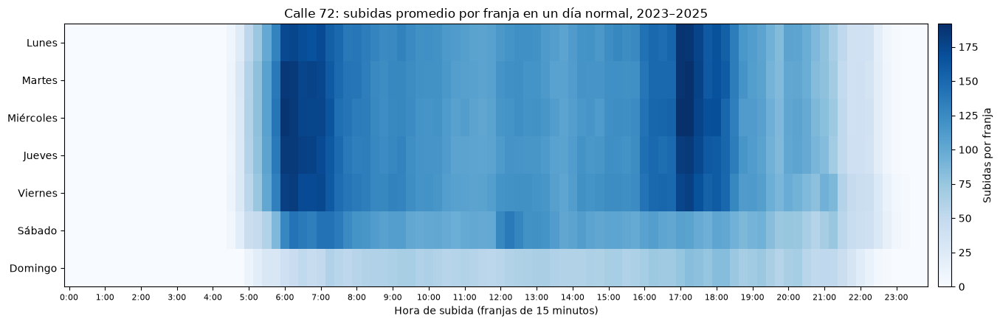

In [32]:
fig, ax = plt.subplots(figsize=(15, 4.5))
im = ax.imshow(mapa.values, aspect="auto", cmap="Blues")

ax.set_yticks(range(len(mapa.index)))
ax.set_yticklabels(mapa.index)
ax.set_xticks(range(0, 96, 4))
ax.set_xticklabels([f"{h}:00" for h in range(24)], rotation=0, fontsize=8)
ax.set_xlabel("Hora de subida (franjas de 15 minutos)")
ax.set_title("Calle 72: subidas promedio por franja en un día normal, 2023–2025")

cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label("Subidas por franja")
plt.tight_layout()
plt.show()

De lunes a viernes, la demanda se concentra en dos bandas: una en la mañana, entre las 6:00 y las 7:15, y otra en la tarde, entre las 17:00 y las 18:15. Entre ambas, la demanda se mantiene en un nivel intermedio y estable. Los cinco días hábiles muestran el mismo patrón, con el mismo horario e intensidad similar. El sábado tiene una banda en la mañana más débil que la de los días hábiles, una franja de mayor demanda alrededor de las 12:00–12:30 y no presenta la banda de la tarde. El domingo tiene una demanda baja y pareja durante todo el día. En todos los días no hay subidas entre la medianoche y las 4:30.

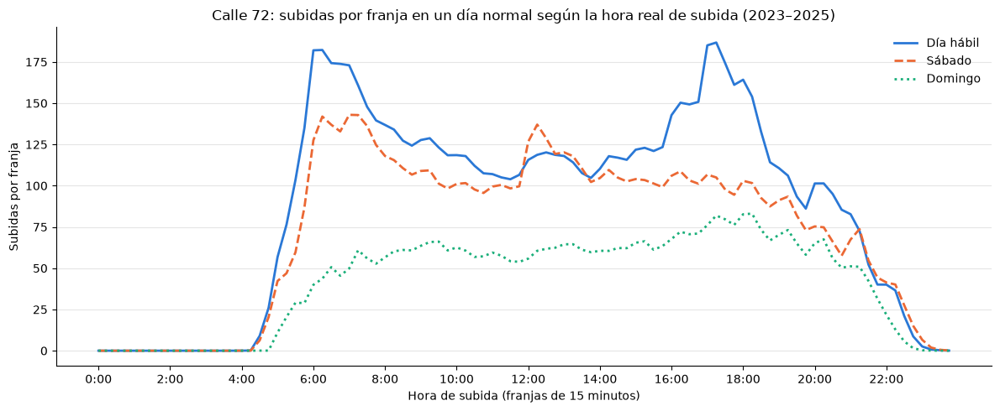

In [33]:
curva_real = pd.DataFrame({
    "Día hábil": mapa.loc[["Lunes", "Martes", "Miércoles", "Jueves", "Viernes"]].mean(),
    "Sábado": mapa.loc["Sábado"],
    "Domingo": mapa.loc["Domingo"],
})

estilos = {"Día hábil": ("#2a78d6", "-"), "Sábado": ("#eb6834", "--"), "Domingo": ("#1baf7a", ":")}

fig, ax = plt.subplots(figsize=(12, 5))
for col, (color, ls) in estilos.items():
    ax.plot(curva_real.index, curva_real[col], color=color, linestyle=ls, linewidth=2, label=col)

ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h}:00" for h in range(0, 24, 2)])
ax.set_xlabel("Hora de subida (franjas de 15 minutos)")
ax.set_ylabel("Subidas por franja")
ax.set_title("Calle 72: subidas por franja en un día normal según la hora real de subida (2023–2025)")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

En un día hábil, las subidas empiezan a las 4:30, suben rápidamente hasta el pico de la mañana, bajan hacia el mediodía, se mantienen en un nivel intermedio durante el día, vuelven a subir hasta el pico de la tarde y descienden después de las 18:15 hasta terminar hacia las 23:00. El sábado tiene un pico temprano en la mañana y otro al mediodía, sin un segundo pico en la tarde. El domingo empieza a las 5:00 y se mantiene bajo y estable durante el día, con su máximo al final de la tarde.

In [34]:
def hora_txt(h):
    return f"{int(h)}:{int(round(h % 1 * 60)):02d}"

filas = []
for col in curva_real.columns:
    s = curva_real[col]
    for nombre, tramo in [("mañana", s[s.index < 12]), ("tarde", s[s.index >= 12])]:
        filas.append({"tipo_dia": col, "periodo": nombre,
                      "franja_max": hora_txt(tramo.idxmax()),
                      "subidas_franja_max": round(tramo.max()),
                      "primera_franja_con_subidas": hora_txt(s[s > 1].index.min()),
                      "ultima_franja_con_subidas": hora_txt(s[s > 1].index.max())})
pd.DataFrame(filas)

,tipo_dia,periodo,franja_max,subidas_franja_max,primera_franja_con_subidas,ultima_franja_con_subidas
0,Día hábil,mañana,6:15,182,4:30,23:00
1,Día hábil,tarde,17:15,187,4:30,23:00
2,Sábado,mañana,7:00,143,4:30,23:15
3,Sábado,tarde,12:15,137,4:30,23:15
4,Domingo,mañana,9:30,66,5:00,22:45
5,Domingo,tarde,18:15,83,5:00,22:45


- Día hábil: 6:15 en la mañana (182 subidas por franja) y 17:15 en la tarde (187). El pico de la tarde es ligeramente mayor que el de la mañana.
- Sábado:7:00 en la mañana (143) y 12:15 al mediodía (137).
- Domingo: 9:30 en la mañana (66) y 18:15 en la tarde (83).

Las subidas comienzan a las 4:30 en días hábiles y sábados, y a las 5:00 los domingos, igual que la primera salida programada. Las últimas subidas se registran a las 23:00 en días hábiles, a las 23:15 los sábados y a las 22:45 los domingos, después de la última salida (20:36 en días hábiles), dentro de la duración de los viajes nocturnos.

### Días especiales frente a un día normal

Cada fecha se asigna a un solo tipo de día según el calendario de temporadas, con el siguiente orden de prioridad cuando pertenece a varias temporadas: festivo, Carnaval (días centrales), Precarnaval, Semana Santa, Fiestas de la Virgen del Carmen. Las fechas que no son especiales se clasifican como día hábil (lunes a viernes), sábado o domingo.

In [35]:
# Temporadas especiales de cada fecha (sin "Días corrientes")
esp = cal_dias[cal_dias["tipo"] != "DIAS_CORRIENTES"].copy()
esp["fecha"] = pd.to_datetime(esp["fecha"])

def categoria(fila):
    if fila["tipo"] == "FESTIVO_NACIONAL":
        return "Festivo"
    if "Días centrales" in fila["nombre"]:
        return "Carnaval (días centrales)"
    if "Precarnaval" in fila["nombre"]:
        return "Precarnaval"
    if fila["nombre"] == "Semana Santa":
        return "Semana Santa"
    if "Virgen del Carmen" in fila["nombre"]:
        return "Virgen del Carmen"
    return "Otro"

esp["categoria"] = esp.apply(categoria, axis=1)

prioridad = ["Festivo", "Carnaval (días centrales)", "Precarnaval", "Semana Santa", "Virgen del Carmen"]
esp["orden"] = esp["categoria"].map({c: i for i, c in enumerate(prioridad)})
tipo_especial = esp.sort_values("orden").drop_duplicates("fecha").set_index("fecha")["categoria"]

# Tipo de día de todas las fechas con datos
fechas = pd.DataFrame({"fecha": pd.to_datetime(demanda72["fecha"].unique())})
fechas["dia_semana"] = fechas["fecha"].dt.dayofweek + 1
fechas["tipo_dia"] = fechas["fecha"].map(tipo_especial)
fechas.loc[fechas["tipo_dia"].isna(), "tipo_dia"] = fechas["dia_semana"].map(
    lambda x: "Día hábil" if x <= 5 else ("Sábado" if x == 6 else "Domingo"))

# Cuántos días hay de cada tipo y en qué días de la semana caen
pd.crosstab(fechas["tipo_dia"], fechas["dia_semana"].map(

    {1: "lun", 2: "mar", 3: "mié", 4: "jue", 5: "vie", 6: "sáb", 7: "dom"}), margins=True)

dia_semana,dom,jue,lun,mar,mié,sáb,vie,All
tipo_dia,,,,,,,,
Carnaval (días centrales),3,0,3,3,0,3,0,12
Domingo,136,0,0,0,0,0,0,136
Día hábil,0,141,112,141,141,0,144,679
Festivo,3,7,33,0,4,1,4,52
Precarnaval,3,3,3,3,3,3,2,20
Semana Santa,5,0,2,3,3,3,0,16
Sábado,0,0,0,0,0,142,0,142
Virgen del Carmen,1,0,0,1,1,0,0,3
All,151,151,153,151,152,152,150,1060


Los 1.060 días con datos se distribuyen así: 679 días hábiles, 142 sábados, 136 domingos, 52 festivos, 20 días de Precarnaval, 16 de Semana Santa (sin contar sus festivos), 12 días centrales del Carnaval y 3 días de la Virgen del Carmen. Los festivos caen en su mayoría en lunes y los días centrales del Carnaval caen siempre de sábado a martes.

In [36]:
d = demanda72.copy()
d["hora_num"] = d["franja"].dt.hour + d["franja"].dt.minute / 60

franjas = np.arange(0, 24, 0.25)
idx = pd.MultiIndex.from_product([fechas["fecha"], franjas], names=["fecha", "hora_num"])
sub_todas = (d.groupby(["fecha", "hora_num"])["subidas"].sum()
              .reindex(idx, fill_value=0).reset_index()
              .merge(fechas[["fecha", "tipo_dia"]], on="fecha"))

curvas_tipo = sub_todas.groupby(["tipo_dia", "hora_num"])["subidas"].mean().unstack("tipo_dia")

# Resumen: total del día y parecido de la forma con un día hábil y con un domingo
resumen_tipo = pd.DataFrame({
    "dias": fechas["tipo_dia"].value_counts(),
    "subidas_dia": curvas_tipo.sum().round(0),
    "pct_vs_dia_habil": (100 * curvas_tipo.sum() / curvas_tipo["Día hábil"].sum()).round(1),
    "corr_forma_dia_habil": curvas_tipo.corrwith(curvas_tipo["Día hábil"]).round(3),
    "corr_forma_domingo": curvas_tipo.corrwith(curvas_tipo["Domingo"]).round(3),
}).sort_values("subidas_dia", ascending=False)
resumen_tipo

,dias,subidas_dia,pct_vs_dia_habil,corr_forma_dia_habil,corr_forma_domingo
tipo_dia,,,,,
Día hábil,679,8511.0,100.0,1.000,0.900
Precarnaval,20,8351.0,98.1,0.995,0.913
Sábado,142,6997.0,82.2,0.951,0.892
Virgen del Carmen,3,6623.0,77.8,0.985,0.914
Semana Santa,16,5729.0,67.3,0.984,0.950
Carnaval (días centrales),12,4195.0,49.3,0.934,0.966
Domingo,136,4063.0,47.7,0.900,1.000
Festivo,52,3497.0,41.1,0.910,0.986


Respecto a un día hábil (8.511 subidas en promedio), el Precarnaval tiene el 98,1 % de la demanda, el sábado el 82,2 %, la Virgen del Carmen el 77,8 %, la Semana Santa el 67,3 %, los días centrales del Carnaval el 49,3 %, el domingo el 47,7 % y los festivos el 41,1 %. En la forma de la curva, el Precarnaval es prácticamente igual a un día hábil (correlación de 0,995). Los festivos tienen la forma de un domingo (0,986 con el domingo frente a 0,910 con el día hábil), y los días centrales del Carnaval también se parecen más a un domingo (0,966 frente a 0,934), aunque con un nivel de demanda algo mayor. La Semana Santa y la Virgen del Carmen se parecen más a un día hábil en forma (0,984 y 0,985), con un nivel intermedio de demanda. El sábado tiene una correlación de 0,951 con el día hábil, la más baja entre los tipos de día que se parecen al día hábil.

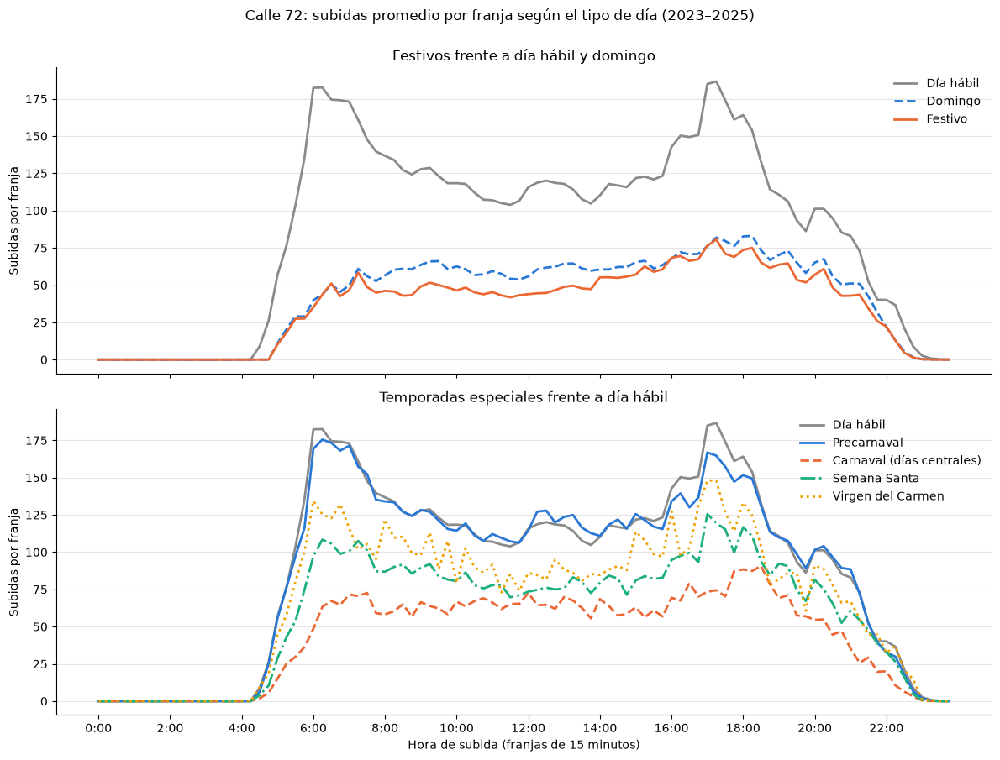

In [37]:
xt = range(0, 24, 2)
xl = [f"{h}:00" for h in xt]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True, sharey=True)

# Panel 1: festivo frente a día hábil y domingo
ax1.plot(curvas_tipo.index, curvas_tipo["Día hábil"], color="#8a8a8a", linewidth=2, label="Día hábil")
ax1.plot(curvas_tipo.index, curvas_tipo["Domingo"], color="#2a78d6", linewidth=2, linestyle="--", label="Domingo")
ax1.plot(curvas_tipo.index, curvas_tipo["Festivo"], color="#eb6834", linewidth=2, label="Festivo")
ax1.set_title("Festivos frente a día hábil y domingo")

# Panel 2: temporadas especiales frente a día hábil
ax2.plot(curvas_tipo.index, curvas_tipo["Día hábil"], color="#8a8a8a", linewidth=2, label="Día hábil")
otros = {"Precarnaval": ("#2a78d6", "-"), "Carnaval (días centrales)": ("#eb6834", "--"),
         "Semana Santa": ("#1baf7a", "-."), "Virgen del Carmen": ("#eda100", ":")}
for col, (color, ls) in otros.items():
    if col in curvas_tipo:
        ax2.plot(curvas_tipo.index, curvas_tipo[col], color=color, linestyle=ls, linewidth=2, label=col)
ax2.set_title("Temporadas especiales frente a día hábil")

for ax in (ax1, ax2):
    ax.set_ylabel("Subidas por franja")
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper right")
ax2.set_xticks(xt)
ax2.set_xticklabels(xl)
ax2.set_xlabel("Hora de subida (franjas de 15 minutos)")
fig.suptitle("Calle 72: subidas promedio por franja según el tipo de día (2023–2025)", y=1.0)
plt.tight_layout()
plt.show()

Los festivos y los domingos tienen curvas casi iguales: sin pico en la mañana, una demanda baja y estable durante el día y un máximo al final de la tarde. El Precarnaval sigue la curva de un día hábil, con los mismos picos de la mañana y de la tarde. La Semana Santa y la Virgen del Carmen conservan esos dos picos, con menor nivel. Los días centrales del Carnaval no tienen picos marcados y su demanda baja desde las 19:00.

Hay tres patrones: dos picos y nivel alto (día hábil y Precarnaval); dos picos y nivel intermedio (Semana Santa y Virgen del Carmen); y sin picos y nivel bajo (domingo, festivos y Carnaval días centrales). El sábado tiene un patrón propio: picos a las 7:00 y a las 12:15, y ninguno en la tarde.

### Tendencia 2023–2025

Se compara la demanda de cada año por tipo de día, por hora del día y por mes.

In [38]:
sub_todas["ano"] = pd.to_datetime(sub_todas["fecha"]).dt.year

por_dia = (sub_todas.groupby(["tipo_dia", "ano", "fecha"])["subidas"].sum()   # total de cada fecha
                    .groupby(["tipo_dia", "ano"]).mean()                       # promedio por tipo y año
                    .unstack("ano").round(0))

por_dia["var_23_24_%"] = (100 * (por_dia[2024] / por_dia[2023] - 1)).round(1)
por_dia["var_24_25_%"] = (100 * (por_dia[2025] / por_dia[2024] - 1)).round(1)
por_dia["var_23_25_%"] = (100 * (por_dia[2025] / por_dia[2023] - 1)).round(1)
por_dia.loc[["Día hábil", "Sábado", "Domingo", "Festivo"]]

ano,2023,2024,2025,var_23_24_%,var_24_25_%,var_23_25_%
tipo_dia,,,,,,
Día hábil,9046.0,8631.0,7861.0,-4.6,-8.9,-13.1
Sábado,7458.0,7146.0,6394.0,-4.2,-10.5,-14.3
Domingo,4287.0,4103.0,3798.0,-4.3,-7.4,-11.4
Festivo,3566.0,3569.0,3339.0,0.1,-6.4,-6.4


Las subidas de un día hábil bajan de 9.046 en 2023 a 8.631 en 2024 (−4,6 %) y a 7.861 en 2025 (−8,9 %), una caída acumulada del 13,1 %. El sábado tiene la mayor caída: de 7.458 a 6.394 subidas (−14,3 %). El domingo baja de 4.287 a 3.798 (−11,4 %). Los festivos se mantienen estables entre 2023 y 2024 (3.566 y 3.569) y bajan un 6,4 % en 2025. En todos los tipos de día, la mayor parte de la caída ocurre entre 2024 y 2025.

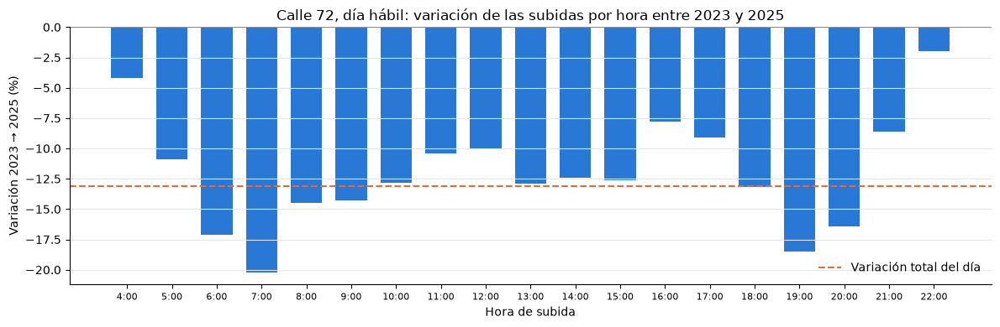

ano,2023,2024,2025,var_23_25_%
hora,,,,
4,35.0,37.0,34.0,-4.0
5,378.0,402.0,337.0,-11.0
6,768.0,736.0,637.0,-17.0
7,688.0,628.0,549.0,-20.0
8,556.0,536.0,475.0,-14.0
9,530.0,510.0,454.0,-14.0
10,482.0,465.0,420.0,-13.0
11,440.0,434.0,394.0,-10.0
12,496.0,478.0,446.0,-10.0


In [39]:
habil = sub_todas[sub_todas["tipo_dia"] == "Día hábil"].copy()
habil["hora"] = habil["hora_num"].astype(int)

por_hora = (habil.groupby(["ano", "fecha", "hora"])["subidas"].sum()     # subidas de cada hora en cada fecha
                 .groupby(["ano", "hora"]).mean()
                 .unstack("ano"))
por_hora = por_hora[por_hora[2023] > 20]                                 # solo horas con operación
por_hora["var_23_25_%"] = (100 * (por_hora[2025] / por_hora[2023] - 1)).round(1)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(por_hora.index, por_hora["var_23_25_%"], color="#2a78d6", width=0.7)
ax.axhline(0, color="#8a8a8a", linewidth=0.8)
ax.axhline(100 * (por_hora[2025].sum() / por_hora[2023].sum() - 1), color="#eb6834",
           linestyle="--", linewidth=1.5, label="Variación total del día")
ax.set_xticks(por_hora.index)
ax.set_xticklabels([f"{h}:00" for h in por_hora.index], fontsize=8)
ax.set_xlabel("Hora de subida")
ax.set_ylabel("Variación 2023 → 2025 (%)")
ax.set_title("Calle 72, día hábil: variación de las subidas por hora entre 2023 y 2025")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

por_hora.round(0)

Todas las horas tienen menos subidas en 2025 que en 2023, pero la caída no es pareja. Las mayores caídas están en el pico de la mañana, a las 7:00 (−20 %) y a las 6:00 (−17 %), y al final de la tarde, a las 19:00 (−18 %) y a las 20:00 (−16 %). Entre las 8:00 y las 15:00 la caída está entre −10 % y −14 %, cerca del total del día (−13,1 %). Las menores caídas son a las 16:00 (−8 %) y a las 17:00 (−9 %), que corresponde al pico de la tarde, a las 21:00 (−9 %) y en los extremos de la operación, a las 4:00 (−4 %) y a las 22:00 (−2 %).

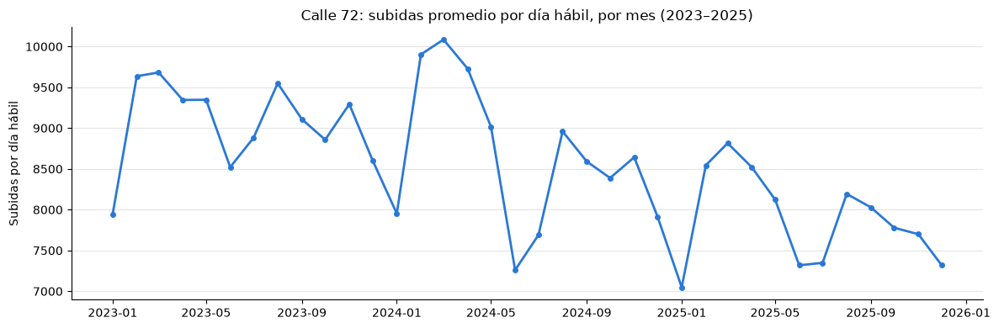

In [40]:
mensual = (habil.groupby("fecha")["subidas"].sum().reset_index()
                .assign(mes=lambda x: pd.to_datetime(x["fecha"]).dt.to_period("M").dt.to_timestamp())
                .groupby("mes")["subidas"].mean())

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(mensual.index, mensual.values, color="#2a78d6", linewidth=2, marker="o", markersize=4)
ax.set_ylabel("Subidas por día hábil")
ax.set_title("Calle 72: subidas promedio por día hábil, por mes (2023–2025)")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Las subidas por día hábil varían entre ≈ 7.040 (enero de 2025) y ≈ 10.090 (marzo de 2024). Hay un patrón que se repite cada año: enero es bajo (≈ 7.940, 7.950 y 7.040 en 2023, 2024 y 2025), febrero y marzo son los meses más altos, junio y julio vuelven a ser bajos (entre ≈ 7.260 y 8.880) y agosto tiene un repunte (≈ 9.550, 8.960 y 8.190). De septiembre a diciembre la demanda disminuye gradualmente; diciembre es bajo en 2024 y 2025 (≈ 7.910 y 7.320) y algo más alto en 2023 (≈ 8.600). Los picos y los valles de cada año son menores que los del año anterior, con excepción de febrero–abril de 2024, que superan a los de 2023.

### Oferta frente a demanda por hora

Se compara, para cada tipo de día, la distribución a lo largo del día de las salidas programadas (`progvehiculos`), de los buses en circulación y de las subidas. Como son medidas de distinta escala, en el gráfico cada una se expresa como porcentaje del total del día.

In [41]:
salidas_fecha = pd.read_sql("""
    SELECT fechasalida::date AS fecha,
           EXTRACT(HOUR FROM fechasalida)::int AS hora,
           COUNT(*) AS salidas
    FROM progvehiculos
    WHERE idruta = 21 AND finalizado = 'S'
      AND fechasalida >= '2023-01-01' AND fechasalida < '2026-01-01'
    GROUP BY 1, 2
""", engine)
salidas_fecha["fecha"] = pd.to_datetime(salidas_fecha["fecha"])
salidas_fecha = salidas_fecha.merge(fechas[["fecha", "tipo_dia"]], on="fecha")

# Subidas y buses en circulación por fecha y hora (de demanda72)
d = demanda72.merge(fechas[["fecha", "tipo_dia"]], on="fecha")
d["hora"] = d["franja"].dt.hour
sub_hora = d.groupby(["fecha", "tipo_dia", "hora"]).agg(subidas=("subidas", "sum"),
                                                        buses=("viajes", "max")).reset_index()

tipos = ["Día hábil", "Sábado", "Domingo"]
comp = {}
for t in tipos:
    n_dias = (fechas["tipo_dia"] == t).sum()
    s = salidas_fecha[salidas_fecha["tipo_dia"] == t].groupby("hora")["salidas"].sum() / n_dias
    u = sub_hora[sub_hora["tipo_dia"] == t].groupby("hora")["subidas"].sum() / n_dias
    b = sub_hora[sub_hora["tipo_dia"] == t].groupby("hora")["buses"].mean()
    comp[t] = pd.DataFrame({"salidas_por_dia": s, "subidas_por_dia": u, "buses_en_circulacion": b}).fillna(0)

comp["Día hábil"].round(1)

,salidas_por_dia,subidas_por_dia,buses_en_circulacion
hora,,,
0,0.0,0.0,1.0
3,0.0,0.0,1.0
4,2.9,35.4,3.1
5,14.6,372.4,16.2
6,6.6,713.5,23.5
7,6.0,621.4,26.2
8,5.3,522.2,27.0
9,5.2,497.9,27.0
10,4.9,455.7,27.0


En un día hábil hay en promedio ≈ 91 salidas de viajes finalizados. La hora de las 5:00 concentra 14,6 salidas, mientras que entre las 6:00 y las 20:00 hay entre 3,3 y 6,6 salidas por hora; desde las 21:00 no hay salidas. Los buses en circulación suben de ≈ 3 a las 4:00 a ≈ 24 a las 6:00, se mantienen en 26–27 de las 7:00 a las 10:00 y entre 24 y 27 de las 12:00 a las 20:00, y bajan a ≈ 12 a las 22:00. Las subidas por hora alcanzan su máximo a las 6:00 (≈ 714) y a las 17:00 (≈ 707), y suman ≈ 8.511 en el día.

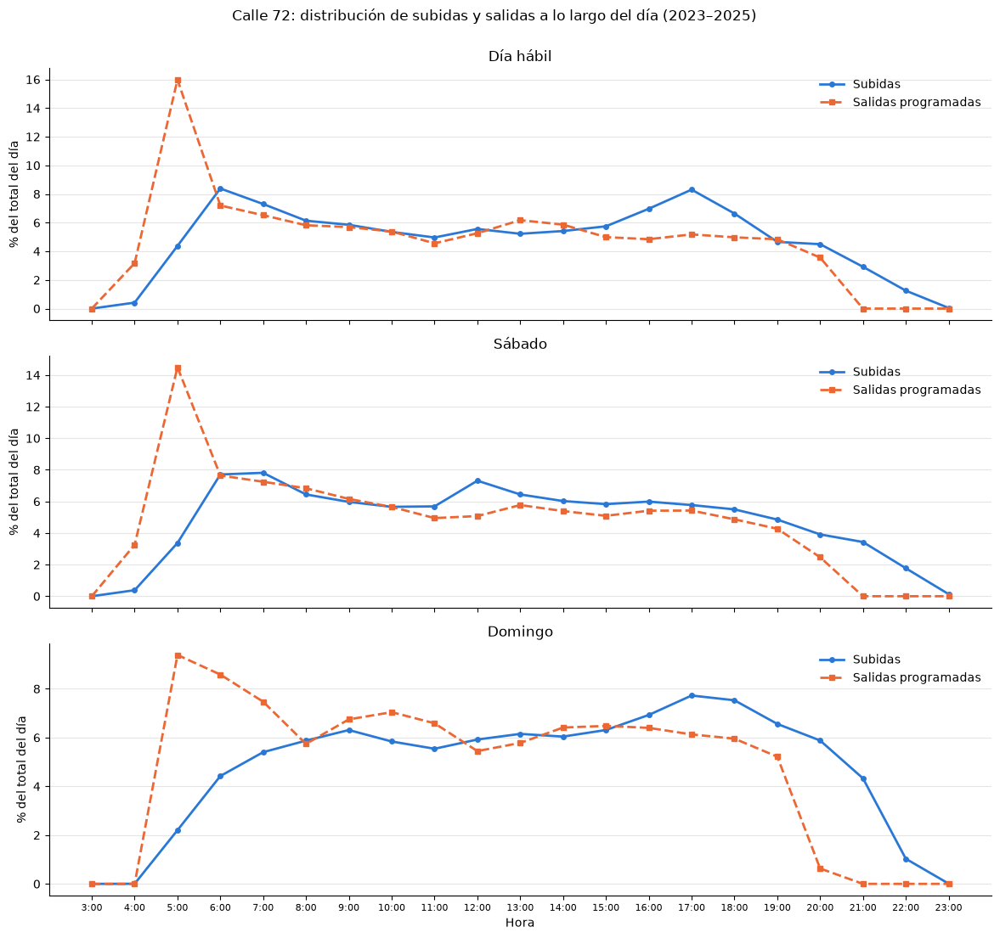

In [42]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

for ax, t in zip(axes, tipos):
    c = comp[t].loc[3:]
    ax.plot(c.index, 100 * c["subidas_por_dia"] / c["subidas_por_dia"].sum(),
            color="#2a78d6", linewidth=2, marker="o", markersize=4, label="Subidas")
    ax.plot(c.index, 100 * c["salidas_por_dia"] / c["salidas_por_dia"].sum(),
            color="#eb6834", linewidth=2, linestyle="--", marker="s", markersize=4, label="Salidas programadas")
    ax.set_title(t)
    ax.set_ylabel("% del total del día")
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper right")

axes[-1].set_xticks(range(3, 24))
axes[-1].set_xticklabels([f"{h}:00" for h in range(3, 24)], fontsize=8)
axes[-1].set_xlabel("Hora")
fig.suptitle("Calle 72: distribución de subidas y salidas a lo largo del día (2023–2025)", y=1.0)
plt.tight_layout()
plt.show()

En los tres tipos de día, las salidas se concentran al inicio de la operación, mientras que las subidas a esa hora son pocas: en un día hábil, la hora de las 5:00 reúne el 16,0 % de las salidas y solo el 4,4 % de las subidas. En los días hábiles, la proporción de subidas supera a la de salidas entre las 6:00 y las 8:00 (8,4 % frente a 7,2 % a las 6:00) y, sobre todo, entre las 16:00 y las 18:00: a las 17:00 ocurre el 8,3 % de las subidas y el 5,1 % de las salidas. Entre las 9:00 y las 15:00 ambas proporciones son similares (entre 5 % y 6 %). Los sábados las dos curvas coinciden casi todo el día, salvo al mediodía, cuando la proporción de subidas es mayor. Los domingos, en las primeras horas la proporción de salidas supera a la de subidas, y entre las 17:00 y las 21:00 ocurre lo contrario. En todos los días hay subidas hasta las 22:00–23:00, después de la última salida.

In [43]:
filas = []
for t in tipos:
    c = comp[t]
    c = c[c["buses_en_circulacion"] > 0]
    r = (c["subidas_por_dia"] / c["buses_en_circulacion"]).round(1)
    filas.append(r.rename(t))
pd.concat(filas, axis=1)

,Día hábil,Sábado,Domingo
hora,,,
0,0.0,0.0,0.0
3,0.0,0.0,0.0
4,11.4,8.2,0.1
5,23.0,15.6,15.1
6,30.3,24.5,16.0
7,23.7,22.3,13.9
8,19.3,17.6,14.0
9,18.4,16.2,15.9
10,16.9,15.3,15.3


El mayor número de subidas por bus en circulación en un día hábil se da a las 6:00 (30,3 por hora) y a las 17:00 (26,9). Entre las 9:00 y las 15:00 está entre 16 y 20, y desde las 19:00 baja de 15 hasta llegar a 9,2 a las 22:00. El sábado el máximo es a las 6:00 (24,5), seguido de las 7:00 (22,3) y las 12:00 (21,1); el resto del día está entre 13 y 18. El domingo los valores son más bajos y estables, entre 14 y 20 de las 5:00 a las 21:00, con los más altos entre las 17:00 y las 21:00 (entre 17,9 y 19,7).

## Distribución y valores atípicos de las subidas diarias

In [44]:
sub_dia = (demanda72.groupby("fecha")["subidas"].sum()
           .rename("subidas").reset_index()
           .merge(fechas[["fecha", "tipo_dia"]], on="fecha"))

# Atípicos dentro de cada tipo de día (regla de 1,5 × RIC)
q1 = sub_dia.groupby("tipo_dia")["subidas"].transform(lambda s: s.quantile(0.25))
q3 = sub_dia.groupby("tipo_dia")["subidas"].transform(lambda s: s.quantile(0.75))
ric = q3 - q1
sub_dia["atipico"] = (sub_dia["subidas"] < q1 - 1.5 * ric) | (sub_dia["subidas"] > q3 + 1.5 * ric)

sub_dia.groupby("tipo_dia")["subidas"].describe().round(0)


,count,mean,std,min,25%,50%,75%,max
tipo_dia,,,,,,,,
Carnaval (días centrales),12.0,4195.0,1079.0,3148.0,3467.0,3856.0,4407.0,6311.0
Domingo,136.0,4063.0,479.0,2444.0,3772.0,4042.0,4370.0,5709.0
Día hábil,679.0,8511.0,1008.0,3754.0,7842.0,8557.0,9261.0,10568.0
Festivo,52.0,3497.0,806.0,1045.0,3146.0,3606.0,3888.0,5105.0
Precarnaval,20.0,8351.0,2079.0,4132.0,7185.0,9248.0,9759.0,10218.0
Semana Santa,16.0,5729.0,1796.0,3443.0,4208.0,5736.0,7536.0,7993.0
Sábado,142.0,6997.0,697.0,4426.0,6452.0,7066.0,7505.0,8402.0
Virgen del Carmen,3.0,6623.0,2240.0,4088.0,5766.0,7443.0,7890.0,8337.0


Por mediana, el Precarnaval (9.248 subidas) supera al día hábil (8.557), seguido de la Virgen del Carmen (7.443), el sábado (7.066), la Semana Santa (5.736), el domingo (4.042), los días centrales del Carnaval (3.856) y los festivos (3.606). Los tipos de día con más observaciones tienen poca dispersión: el 50 % central de los días hábiles está entre 7.842 y 9.261 subidas, el de los sábados entre 6.452 y 7.505 y el de los domingos entre 3.772 y 4.370. Los tipos de día con pocas observaciones tienen rangos amplios: el Precarnaval va de 4.132 a 10.218 subidas, la Semana Santa de 3.443 a 7.993 y los días centrales del Carnaval de 3.148 a 6.311.

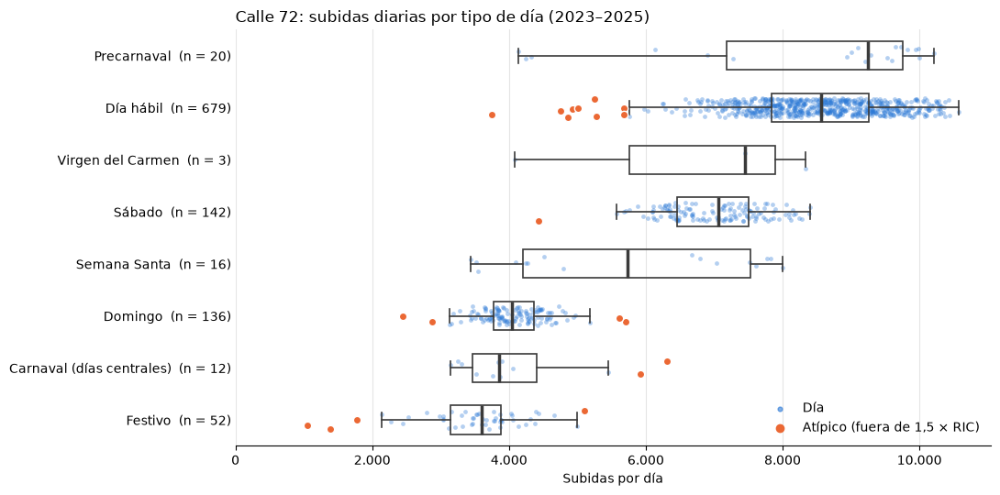

In [45]:
# Tipos de día ordenados por mediana (el de mayor demanda arriba)
orden = sub_dia.groupby("tipo_dia")["subidas"].median().sort_values().index
n_dias = sub_dia["tipo_dia"].value_counts()

fig, ax = plt.subplots(figsize=(11, 5.5))
rng = np.random.default_rng(1)

# Un punto por día (con un pequeño desplazamiento vertical para que no se tapen)
for i, t in enumerate(orden):
    g = sub_dia[sub_dia["tipo_dia"] == t]
    y = i + rng.uniform(-0.18, 0.18, len(g))
    normal, atip = ~g["atipico"].values, g["atipico"].values
    ax.scatter(g["subidas"][normal], y[normal], s=12, color="#2a78d6", alpha=0.35, linewidths=0, zorder=2)
    ax.scatter(g["subidas"][atip], y[atip], s=36, color="#eb6834", edgecolors="white", linewidths=1, zorder=4)

# Cajas sin relleno encima de los puntos
ax.boxplot([sub_dia.loc[sub_dia["tipo_dia"] == t, "subidas"] for t in orden],
           positions=range(len(orden)), orientation= "horizontal", widths=0.55, showfliers=False,
           patch_artist=True, zorder=3,
           boxprops=dict(facecolor="none", edgecolor="#3a3a3a", linewidth=1.2),
           whiskerprops=dict(color="#3a3a3a", linewidth=1.2),
           capprops=dict(color="#3a3a3a", linewidth=1.2),
           medianprops=dict(color="#3a3a3a", linewidth=2.5))

ax.set_yticks(range(len(orden)))
ax.set_yticklabels([f"{t}  (n = {n_dias[t]})" for t in orden])
ax.set_xlabel("Subidas por día")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.set_xlim(left=0)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

ax.scatter([], [], s=12, color="#2a78d6", alpha=0.6, label="Día")
ax.scatter([], [], s=36, color="#eb6834", label="Atípico (fuera de 1,5 × RIC)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Calle 72: subidas diarias por tipo de día (2023–2025)", loc="left")
plt.tight_layout()
plt.show()

In [46]:
atipicos = sub_dia[sub_dia["atipico"]].sort_values(["tipo_dia", "subidas"]).copy()
atipicos["dia_semana"] = atipicos["fecha"].dt.day_name()
atipicos

,fecha,subidas,tipo_dia,atipico,dia_semana
47,2023-02-18,5926.0,Carnaval (días centrales),True,Saturday
392,2024-02-10,6311.0,Carnaval (días centrales),True,Saturday
610,2024-09-22,2444.0,Domingo,True,Sunday
508,2024-06-09,2870.0,Domingo,True,Sunday
677,2024-12-01,5611.0,Domingo,True,Sunday
339,2023-12-17,5709.0,Domingo,True,Sunday
594,2024-09-06,3754.0,Día hábil,True,Friday
871,2025-06-19,4748.0,Día hábil,True,Thursday
708,2025-01-02,4862.0,Día hábil,True,Thursday
533,2024-07-05,4926.0,Día hábil,True,Friday


Hay 20 días atípicos dentro de su tipo de día:

- Festivos (4):los tres 1 de enero, por debajo de lo normal (1.780 en 2023, 1.045 en 2024 y 1.386 en 2025), y el 1 de mayo de 2024, por encima (5.105).
- Días hábiles (9), todos por debajo de lo normal: tres son 2 de enero (2023, 2024 y 2025), uno es el 24 de diciembre de 2025, y los otros cinco son el 6 de septiembre de 2024 (3.754 subidas), el 19 de junio de 2025, el 5 de julio de 2024, el 29 de julio de 2025 y el 9 de julio de 2025.
- Domingos (4): dos por debajo de lo normal (9 de junio y 22 de septiembre de 2024, con 2.870 y 2.444 subidas) y dos por encima (17 de diciembre de 2023 y 1 de diciembre de 2024, con 5.709 y 5.611).
- Sábado (1): el 15 de junio de 2024, por debajo de lo normal (4.426).
- Carnaval (2): el 18 de febrero de 2023 y el 10 de febrero de 2024, ambos sábados, por encima del resto de días centrales (5.926 y 6.311).

In [47]:
viajes_0609 = pd.read_sql(text("""
    SELECT idprogramacion, finalizado
    FROM progvehiculos
    WHERE idruta = 21 AND fechainicio::date = '2024-09-06'
"""), engine)

reg_0609 = pd.read_sql(text("""
    SELECT idprogramacion, COUNT(*) AS registros, SUM(cantidad_subida) AS subidas
    FROM conteo_pasajeros_destino
    WHERE idprogramacion = ANY(:ids)
    GROUP BY idprogramacion
"""), engine, params={"ids": viajes_0609["idprogramacion"].tolist()})

print(f"Viajes programados: {len(viajes_0609)} | finalizados: {(viajes_0609['finalizado'] == 'S').sum()}")
print(f"Viajes con registros de conteo: {len(reg_0609)} | subidas: {reg_0609['subidas'].sum()}")

Viajes programados: 36 | finalizados: 21
Viajes con registros de conteo: 35 | subidas: 3754.0


El 6 de septiembre de 2024, el día hábil con menos subidas, la ruta tuvo 36 viajes programados (≈ 97 en un día hábil normal), de los cuales solo 21 se finalizaron; 35 de los 36 tienen registros en `conteo_pasajeros_destino`.

## Dependencia temporal

Se mide cuánto se relacionan las subidas de un día con las de días anteriores, comparando todos los días con solo los días hábiles.

In [48]:
serie = sub_dia.set_index("fecha")["subidas"].sort_index()
serie = serie.reindex(pd.date_range(serie.index.min(), serie.index.max(), freq="D"))

habil_dia = serie.where(serie.index.isin(sub_dia.loc[sub_dia["tipo_dia"] == "Día hábil", "fecha"]))

rezagos = [1, 2, 7, 14, 28, 364]
pd.DataFrame({
    "rezago_dias": rezagos,
    "todos_los_dias": [round(serie.autocorr(lag=r), 3) for r in rezagos],
    "solo_dias_habiles": [round(habil_dia.autocorr(lag=r), 3) for r in rezagos],
})

,rezago_dias,todos_los_dias,solo_dias_habiles
0,1,0.339,0.763
1,2,-0.057,0.714
2,7,0.640,0.632
3,14,0.591,0.563
4,28,0.580,0.360
5,364,0.680,0.571


Con todos los días, la autocorrelación es baja con el día anterior (0,339) y prácticamente nula a dos días (−0,057), y alta con el mismo día de la semana anterior (0,640), de dos semanas antes (0,591) y del año anterior (0,680). El patrón semanal domina la serie: un día se parece más al mismo día de otra semana que al día anterior, porque los días consecutivos suelen ser de tipo distinto (por ejemplo, viernes y sábado).

Con solo días hábiles, la autocorrelación es alta con el día hábil anterior (0,763) y disminuye a medida que los días se alejan: 0,714 a dos días, 0,632 a una semana, 0,563 a dos semanas y 0,360 a cuatro semanas. Con el mismo día del año anterior es de 0,571. Esto indica que, además del tipo de día, la demanda tiene un nivel que cambia de forma gradual en el tiempo, de modo que los días cercanos se parecen más entre sí que los lejanos.

### Horario de salidas por franja de 15 minutos

Para construir las franjas según la hora de salida del bus (`fechasalida` de `progvehiculos`), primero se revisa entre qué horas hay salidas. La tabla muestra, para cada franja de 15 minutos, el porcentaje de días de cada grupo con al menos una salida.

In [49]:
# Salidas por franja de 15 minutos según la hora de salida del bus (progvehiculos.fechasalida)
salidas15 = pd.read_sql("""
    SELECT fechasalida::date AS fecha,
           EXTRACT(HOUR FROM fechasalida)::int * 60
             + floor(EXTRACT(MINUTE FROM fechasalida) / 15)::int * 15 AS minuto_franja,
           COUNT(*) AS salidas
    FROM progvehiculos
    WHERE idruta = 21
      AND fechasalida >= '2023-01-01' AND fechasalida < '2026-01-01'
    GROUP BY 1, 2
""", engine)
salidas15["fecha"] = pd.to_datetime(salidas15["fecha"])
salidas15["hora_num"] = salidas15["minuto_franja"] / 60
salidas15["grupo"] = salidas15["fecha"].dt.dayofweek.map(
    lambda x: "Lunes a viernes" if x <= 4 else ("Sábado" if x == 5 else "Domingo"))

def hhmm(h):
    return f"{int(h)}:{int(round(h % 1 * 60)):02d}"

# Porcentaje de días de cada grupo que tienen al menos una salida en cada franja
dias_grupo = salidas15.groupby("grupo")["fecha"].nunique()
pct_dias = (salidas15.groupby(["grupo", "hora_num"])["fecha"].nunique()
                     .div(dias_grupo, level="grupo").mul(100).round(1)
                     .unstack("grupo")[["Lunes a viernes", "Sábado", "Domingo"]].fillna(0))
pct_dias.index = [hhmm(h) for h in pct_dias.index]

print("Primera y última franja con salidas en al menos la mitad de los días:")
for g in pct_dias.columns:
    con_salida = pct_dias.index[pct_dias[g] >= 50]
    print(f"  {g:16s} {con_salida[0]} a {con_salida[-1]}")
print(f"\nFranja más temprana con alguna salida: {hhmm(salidas15['hora_num'].min())} | "
      f"más tardía: {hhmm(salidas15['hora_num'].max())}")

with pd.option_context("display.max_rows", None):
    display(pct_dias)

Primera y última franja con salidas en al menos la mitad de los días:
  Lunes a viernes  4:30 a 20:30
  Sábado           4:30 a 20:30
  Domingo          5:00 a 19:45

Franja más temprana con alguna salida: 3:30 | más tardía: 20:45


grupo,Lunes a viernes,Sábado,Domingo
3:30,0.1,0.0,0.0
4:00,0.1,0.6,0.6
4:15,0.0,0.0,0.6
4:30,92.8,98.7,1.3
4:45,92.8,99.4,0.6
5:00,99.9,100.0,100.0
5:15,99.9,100.0,100.0
5:30,99.9,100.0,100.0
5:45,99.5,99.4,94.9
6:00,98.9,98.7,100.0


### Subidas por franja de salida

Cada viaje aporta el total de sus subidas (de `conteo_pasajeros_destino`, incluidos los viajes cancelados) a la franja de 15 minutos de su hora de salida. La ventana va de 4:30 a 20:30, el horario de despacho de la ruta; las salidas fuera de esa ventana se asignan a la franja del borde más cercano. Los últimos días de mes se excluyen y las franjas sin salidas cuentan como 0 subidas.

In [52]:
viajes_sal = pd.read_sql("""
    SELECT idprogramacion, fechasalida, fechainicio, fechafin,
           finalizado, cancelada, numeropasajeros
    FROM progvehiculos
    WHERE idruta = 21
      AND fechasalida >= '2023-01-01' AND fechasalida < '2026-01-01'
""", engine)

TOPE_BUG = 10000          # pasajeros por viaje por encima de esto = error del sensor
MAX_FIN_ANTES_MIN = 300   # fechafin anterior a fechasalida por más de 5 h = registro incoherente
DESFASE_MAX_MIN = 30      # si el viaje empezó más de 30 min antes/después de la salida, se usa fechainicio
EXCLUIR_IDS = [5308103, 5308104, 5754538]   # salida de madrugada e inicio ~12 h después (cancelados)
INICIO, FIN = "04:30", "20:30"              # ventana de franjas de salida

v = viajes_sal.copy()
for c in ["fechasalida", "fechainicio", "fechafin"]:
    v[c] = pd.to_datetime(v[c], errors="coerce")
n0 = len(v)

# --- 1. Limpieza ---
sin_pax = v["numeropasajeros"].isna()
bug_sensor = v["numeropasajeros"] >= TOPE_BUG
fin_antes = (v["fechasalida"] - v["fechafin"]).dt.total_seconds() / 60 > MAX_FIN_ANTES_MIN
excl_ids = v["idprogramacion"].isin(EXCLUIR_IDS)

limpieza = pd.DataFrame({
    "criterio": ["Sin numeropasajeros", f"Más de {TOPE_BUG:,} pasajeros (error de sensor)",
                 "fechafin más de 5 h antes de fechasalida", "Salida de madrugada no confiable"],
    "viajes": [sin_pax.sum(), bug_sensor.sum(), fin_antes.sum(), excl_ids.sum()],
    "pasajeros": [0, v.loc[bug_sensor, "numeropasajeros"].sum(),
                  v.loc[fin_antes, "numeropasajeros"].sum(), v.loc[excl_ids, "numeropasajeros"].sum()],
})
display(limpieza)
v = v[~(sin_pax | bug_sensor | fin_antes | excl_ids)].copy()
print(f"Viajes: {n0:,} → {len(v):,}")

# --- 2. Hora de referencia: salida, salvo desfase > 30 min ---
v["desfase_min"] = (v["fechainicio"] - v["fechasalida"]).dt.total_seconds() / 60
corregir = v["desfase_min"].abs() > DESFASE_MAX_MIN
v["hora_ref"] = v["fechasalida"].where(~corregir, v["fechainicio"])

print(f"Hora corregida con fechainicio (desfase > {DESFASE_MAX_MIN} min): {corregir.sum():,} viajes ({corregir.mean():.2%})")

# --- 3. Franja de 15 min y bordes de la ventana ---
v["franja_ts"] = v["hora_ref"].dt.floor("15min")
hhmm_f = v["franja_ts"].dt.strftime("%H:%M")
m_temprano = (hhmm_f >= "04:00") & (hhmm_f < INICIO)
m_tarde = hhmm_f == "20:45"
v.loc[m_temprano, "franja_ts"] = v.loc[m_temprano, "franja_ts"].dt.normalize() + pd.Timedelta(hours=4, minutes=30)
v.loc[m_tarde, "franja_ts"] = v.loc[m_tarde, "franja_ts"].dt.normalize() + pd.Timedelta(hours=20, minutes=30)

hora_f = v["franja_ts"].dt.strftime("%H:%M")
fuera = (hora_f < INICIO) | (hora_f > FIN)
print(f"Reasignados a 4:30: {m_temprano.sum()} | a 20:30: {m_tarde.sum()} | "
      f"fuera de la ventana (excluidos): {fuera.sum()} viajes, {v.loc[fuera, 'numeropasajeros'].sum():,.0f} pasajeros")
v = v[~fuera]

# --- 4. Cuadrícula completa: todas las franjas de cada día, con cero si no hubo salidas ---
h0, m0 = map(int, INICIO.split(":"))
h1, m1 = map(int, FIN.split(":"))
slots = pd.timedelta_range(start=f"{h0}h{m0}min", end=f"{h1}h{m1}min", freq="15min")
n = len(slots)
dias = pd.date_range("2023-01-01", "2025-12-31", freq="D")
esperado = pd.DatetimeIndex([d + s for d in dias for s in slots])

serie_salida = (v.groupby("franja_ts")["numeropasajeros"].sum()
                 .reindex(esperado, fill_value=0).rename("pasajeros"))

# --- 5. Fines de mes: se excluyen solo si en progvehiculos también están vacíos ---
total_dia = serie_salida.groupby(serie_salida.index.normalize()).sum()
med_fin = total_dia[total_dia.index.is_month_end].median()
med_resto = total_dia[~total_dia.index.is_month_end].median()
EXCLUIR_FIN_MES = med_fin < 0.5 * med_resto

print(f"Pasajeros por día — mediana fines de mes: {med_fin:,.0f} | resto: {med_resto:,.0f} "
      f"→ excluir fines de mes: {EXCLUIR_FIN_MES}")
if EXCLUIR_FIN_MES:
    serie_salida[serie_salida.index.normalize().isin(dias_sin_dato)] = np.nan

# --- 6. Partición 80/20 por días: el análisis se hace solo sobre entrenamiento ---
dias_serie = np.sort(serie_salida.index.normalize().unique())
corte = dias_serie[int(len(dias_serie) * 0.8)]
train_salida = serie_salida[serie_salida.index < corte]
print(f"Franjas por día: {n} | días: {len(dias):,} | corte: {pd.Timestamp(corte):%Y-%m-%d} | "
      f"franjas de entrenamiento: {len(train_salida):,} | sin dato: {train_salida.isna().sum():,}")

,criterio,viajes,pasajeros
0,Sin numeropasajeros,1736,0.0
1,"Más de 10,000 pasajeros (error de sensor)",0,0.0
2,fechafin más de 5 h antes de fechasalida,2,100.0
3,Salida de madrugada no confiable,3,26.0


Viajes: 101,883 → 100,142
Hora corregida con fechainicio (desfase > 30 min): 1,863 viajes (1.86%)
Reasignados a 4:30: 0 | a 20:30: 72 | fuera de la ventana (excluidos): 192 viajes, 286 pasajeros
Pasajeros por día — mediana fines de mes: 8,287 | resto: 7,841 → excluir fines de mes: False
Franjas por día: 65 | días: 1,096 | corte: 2025-05-26 | franjas de entrenamiento: 56,940 | sin dato: 0


De los 101.883 viajes de 2023 a 2025 se excluyen 1.736 sin conteo de pasajeros (1,7 %), 2 con `fechafin` más de 5 horas anterior a la salida (100 pasajeros) y 3 viajes cancelados con salida registrada de madrugada e inicio unas 12 horas después (26 pasajeros). Ningún viaje supera los 10.000 pasajeros. La hora de referencia es `fechasalida`; en 1.863 viajes (1,9 %) la salida y el inicio difieren en más de 30 minutos, y para esos se usa `fechainicio`, porque al compararlos con el primer registro de `conteo_pasajeros_destino` el inicio coincide a menos de un minuto y la salida no. Las 72 salidas de las 20:45 se asignan a la franja de 20:30, y 192 viajes que quedan fuera de la ventana (286 pasajeros) se excluyen. Los últimos días de mes sí tienen pasajeros en `progvehiculos` (mediana de 8.287 por día, frente a 7.841 en el resto), por lo que en esta serie no se excluyen. La serie queda con 65 franjas por día durante 1.096 días; el 80 % inicial (hasta el 25 de mayo de 2025) se usa como entrenamiento.

In [53]:
tabla = serie_salida.rename_axis("franja_ts").to_frame()
tabla["franja"]     = tabla.index.time
tabla["anio"]       = tabla.index.year
tabla["mes"]        = tabla.index.month
tabla["dia"]        = tabla.index.day
tabla["dia_semana"] = tabla.index.dayofweek + 1

# Tipo de día: especial según el calendario (sección 6.2); si no, hábil / sábado / domingo
fecha_idx = tabla.index.normalize()
tabla["tipo_dia"] = pd.Series(fecha_idx.map(tipo_especial), index=tabla.index)
tabla["tipo_dia"] = tabla["tipo_dia"].fillna(
    tabla["dia_semana"].map(lambda x: "Día hábil" if x <= 5 else ("Sábado" if x == 6 else "Domingo")))

tabla = tabla[["franja", "anio", "mes", "dia", "dia_semana", "tipo_dia", "pasajeros"]]

# Partición 80/20 por días (mismo corte de la celda anterior)
train_c72   = tabla[tabla.index < corte]
holdout_c72 = tabla[tabla.index >= corte]

DATA_PROCESSED = Path("data") / "processed"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
train_c72.to_parquet(DATA_PROCESSED / "train_c72.parquet")
holdout_c72.to_parquet(DATA_PROCESSED / "holdout_c72.parquet")

print("Guardado:")
print(f"  {DATA_PROCESSED / 'train_c72.parquet'}    — {len(train_c72):,} franjas "
      f"({train_c72.index.min():%Y-%m-%d} → {train_c72.index.max():%Y-%m-%d})")
print(f"  {DATA_PROCESSED / 'holdout_c72.parquet'}  — {len(holdout_c72):,} franjas "
      f"({holdout_c72.index.min():%Y-%m-%d} → {holdout_c72.index.max():%Y-%m-%d})")
print(f"Proporción train: {len(train_c72) / len(tabla):.1%} | holdout: {len(holdout_c72) / len(tabla):.1%}")

Guardado:
  data\processed\train_c72.parquet    — 56,940 franjas (2023-01-01 → 2025-05-25)
  data\processed\holdout_c72.parquet  — 14,300 franjas (2025-05-26 → 2025-12-31)
Proporción train: 79.9% | holdout: 20.1%


### ACF y PACF de la serie por franja de salida

La autocorrelación (ACF) y la autocorrelación parcial (PACF) se calculan solo sobre el periodo de entrenamiento. Un rezago de 65 franjas equivale a un día y uno de 455 a una semana.

In [54]:
serie_acf = train_salida.fillna(train_salida.shift(7 * n))   # sin efecto si no hay días sin dato

fig, axes = plot_acf_pacf(
    serie_acf,
    lags=7 * n + 10,
    xlab=f"Rezago (franjas de 15 min; {n} = 1 día)",
    figsize=(12, 4),
)

La ACF presenta picos en los múltiplos de 65 rezagos, que corresponden a la misma franja de días anteriores, y picos menores cada 32–33 rezagos, a medio día, asociados a los dos picos diarios de pasajeros. Entre picos la autocorrelación es ligeramente negativa (≈ −0,1). La altura de los picos diarios baja de ≈ 0,38 en el rezago 65 a ≈ 0,24 entre los rezagos 195 y 325, y vuelve a subir a ≈ 0,35 en el 390 y ≈ 0,46 en el 455, una semana después: la misma franja de la semana anterior es la más correlacionada. Con las dos franjas inmediatamente anteriores la autocorrelación es moderada (≈ 0,35–0,45).

La PACF es alta en los primeros rezagos (≈ 0,37), tiene un pico en el rezago 65 (≈ 0,17) y picos menores en los siguientes múltiplos de 65. Además de las franjas recientes, la misma franja de días anteriores aporta información propia.

Para separar el ciclo semanal del diario, a cada franja se le resta el valor de la misma franja del día anterior (diferencia de 65 rezagos).

In [55]:
fig, axes = plot_acf_pacf(
    serie_acf.diff(n).dropna(),
    lags=7 * n + 10,
    xlab=f"Rezago (franjas de 15 min; {n} = 1 día)",
    figsize=(12, 4),
)

Con la diferencia diaria desaparecen los picos cada 65 rezagos. Queda una correlación positiva baja con las franjas cercanas (≈ 0,1–0,25 en los primeros 35 rezagos), un valor negativo en el rezago 65 (≈ −0,41), propio de la diferenciación, y un repunte positivo alrededor del rezago 455 (≈ 0,18): el ciclo semanal se mantiene después de quitar el diario. La PACF muestra picos negativos en los múltiplos de 65 que disminuyen poco a poco (de ≈ −0,44 a ≈ −0,1).